# Forecasting Cabai Rawit Merah Prices 7 Working Days Ahead: 6 Indonesian Provinces

**Theme:** Agriculture and Food Systems. **Task type:** time-series forecasting (direct multi-step, 6-series panel).

### Map from the assignment brief (Section 7 "required sections") to this notebook

| Brief section | Here |
|---|---|
| 1 Project overview | Section 1 |
| 2 Dataset description | Section 2 |
| 3 Data-quality assessment | Section 3 |
| 4 Data preparation | Section 4 (including the test-set lock, which comes *before* any feature-informing EDA) |
| 5 Exploratory data analysis | Section 5 |
| 6 Feature engineering | Section 6 (own price, cross-province, weather, calendar, Solar, rejected candidates) |
| 7 Baseline model | Section 8 |
| 8 Candidate models | Section 7 (split logic), Section 9 (five model families, leakage demonstration, feature ablation) |
| 9 Hyperparameter tuning | Section 10 |
| 10 Model evaluation | Section 11 |
| 11 Model interpretation | Section 12 (predictive, **not causal**) |
| 12 Actionable insights / 13 Business implications | Section 13 |
| Limitations, next steps | Section 14 (consolidated), Section 15 |

**Reading guide.** Each step is a markdown cell (what and *why*), then a code cell (with inline comments on non-obvious choices), then a markdown cell interpreting the output and saying what it changes downstream.

## 0. Setup

In [1]:
import warnings, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, pacf, adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

import lightgbm as lgb
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterSampler, KFold

from hijridate import Hijri

# statsmodels/sklearn emit convergence and deprecation chatter that is not actionable here
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", module="statsmodels")

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3, "figure.autolayout": True})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

In [2]:
NB_DIR    = Path.cwd()
# the ONE data path (brief Section 12): PIHPS prices, weather and the Solar column all come from the project dataset folder
DATA_DIR  = NB_DIR.parent / "dataset"
assert DATA_DIR.exists(), f"missing {DATA_DIR} (run the notebook from the analysis/ folder, inside pihps-cabai-rawit-forecast/)"

PROVINCES = ["Jawa Tengah", "DI Yogyakarta", "Jawa Timur", "Bali", "Nusa Tenggara Barat", "DKI Jakarta"]
SHORT = {"Jawa Tengah": "JATENG", "DI Yogyakarta": "DIY", "Jawa Timur": "JATIM", "Bali": "BALI",
         "Nusa Tenggara Barat": "NTB", "DKI Jakarta": "DKI"}

# forecast horizon in WORKING days = rows of the Mon-Fri grid (the project's stated target)
H = 7
# externally measured inputs (weather, other provinces' prices) must be >= 1 day old;
# same convention and default as fetch_weather.py --min-lag
MIN_LAG = 1    

print("pandas", pd.__version__, "| lightgbm", lgb.__version__)

pandas 3.0.6 | lightgbm 4.7.0


## 1. Project overview

**Context.** Cabai rawit merah (red bird's-eye chili) is a staple of Indonesian cooking and one of the country's most volatile food prices. It recurs as a named contributor to monthly inflation in BPS / Bank Indonesia releases.
Prices can double within weeks during a bad rainy season or before Ramadan/Lebaran, then crash at harvest.

**Stakeholder.** The provincial *Tim Pengendalian Inflasi Daerah* (TPID: provincial government, Dinas Perdagangan/Pertanian and the local Bank Indonesia office), plus the agencies that run market operations (*operasi pasar*), such as Perum Bulog or the provincial trade office.
They need **early warning** of where and when chili prices will spike, so they can move stock between regions, schedule market operations or coordinate with producer regions before a spike peaks.

**Predictive question.** *Given everything known at the end of working day t, what will the traditional-market price of cabai rawit merah be in province p on working day t+7?*

| Item | Definition |
|---|---|
| Task type | time-series forecasting, direct multi-step, horizon h = 7 working days (≈ 9-11 calendar days) |
| Target | `price` (Rp/kg, PIHPS province average of traditional markets) on working day t+7 |
| Unit of analysis | one (province, forecast-origin working day t) pair |
| Series | Jawa Tengah, DI Yogyakarta, Jawa Timur, Bali, Nusa Tenggara Barat, DKI Jakarta |
| Framing | **predictive, not causal.** Every "driver" below is a candidate predictor with a plausible mechanism. Nothing here identifies a causal effect. |

**Why cabai rawit merah** (summarised from the project README). It was chosen over flat staples such as rice because:
1. it is the most volatile PIHPS commodity (province CVs of 40-56%), so forecasting it is useful and not trivial;
2. it has about 2,300-2,400 working days of history per province since 2017, which covers several seasonal and holiday cycles;
3. it has plausible external drivers that can be joined in like rainfall (crop damage, harvest timing), religious-holiday demand, cross-region trade and transport cost.

## 2. Dataset description

| Source | What | How it was built | Accessed |
|---|---|---|---|
| **PIHPS Nasional, Bank Indonesia** (bi.go.id/hargapangan) | daily traditional-market price, Rp/kg, commodity 16 (Cabai Rawit Merah), province level plus the national average | `scripts/fetch_pihps.py`: public JSON, one request per quarter, `price_type_id=1` (pasar tradisional), `tipe_laporan=1` (harian). `"-"` cells become NaN. Raw responses are cached | 2026-10-18 |
| **Open-Meteo Historical Weather (ERA5 reanalysis)**, CC BY 4.0 | precipitation, rain, precipitation hours, temperature mean/max/min, relative humidity, shortwave radiation, ET0 at each **provincial capital** | `scripts/fetch_weather.py`: lag/rolling features **shifted by `min_lag`=1 before the join**, with a `check_no_leak()` assertion. Radiation and ET0 get the same 7/30-day rolling-mean construction as temperature and humidity (`srad_mean_*`, `et0_mean_*`), also shifted by `min_lag` | 2026-10-18 |
| **BBM Solar price** (subsidised diesel) | Rp/L in force on each date | `scripts/fetch_bbm.py`: as-of join of `dataset/bbm_price_events.csv`, a hand-compiled table of government price changes with a source and confidence label per row (Kementerian/Ditjen Migas ESDM announcements, ICCT WP 2020-23, Kominfo indonesiabaik.id). Six Solar events 2015-2022, all `confirmed` | table generated 2026-10-18 |
| Holiday calendar | Ramadan, Idul Fitri, Idul Adha, Christmas, Imlek | a dated lookup table, built later in the notebook | n/a |

The modelling file `dataset/pihps_red_cayenne_pepper.csv` is the output of all three fetch scripts: 

one row per (province, working day), `price` plus 25 leak-safe weather features (21 rain/temperature/humidity + 4 radiation/ET0) plus `solar_rp_per_l`, 33 columns in all. It is the only source of model weather and Solar features; the unlagged `weather_daily_raw.csv` is used only for EDA scans, the extra lagged rain windows and leak re-checks.

In [3]:
# Load every input
panel      = pd.read_csv(DATA_DIR / "pihps_red_cayenne_pepper.csv", parse_dates=["date"])  # modelling panel: price + ALL model weather features + Solar
prices_all = pd.read_csv(DATA_DIR / "pihps_prices.csv", parse_dates=["date"])              # also holds the national series
wx_raw     = pd.read_csv(DATA_DIR / "weather_daily_raw.csv", parse_dates=["date"])         # UNLAGGED: EDA scans, the lagged rain windows and leak re-checks only
bbm_ev     = pd.read_csv(DATA_DIR / "bbm_price_events.csv", parse_dates=["effective_date"])  # cited source table behind solar_rp_per_l (documentation + re-check later)
quality    = pd.read_csv(DATA_DIR / "pihps_quality.csv")
meta_p     = json.loads((DATA_DIR / "pihps_meta.json").read_text())
meta_w     = json.loads((DATA_DIR / "weather_meta.json").read_text())
meta_b     = json.loads((DATA_DIR / "bbm_meta.json").read_text())

print("modelling panel:", panel.shape, "| dates", panel.date.min().date(), "->", panel.date.max().date())
print("PIHPS accessed:", meta_p["accessed_at"], "| weather accessed:", meta_w["accessed_at"], "| weather min_lag:", meta_w["min_lag_days"],
      "| BBM table generated:", meta_b["generated_at"][:10])

# Weather features already built (and shifted by min_lag) in fetch_weather.py. Two groups, so the ablation can judge them separately:
WEATHER_BASE = [c for c in panel.columns if c.startswith(("rain_", "temp_", "rh_"))]   # rainfall, temperature, humidity
WX_EXTRA     = [c for c in panel.columns if c.startswith(("srad_", "et0_"))]          # shortwave radiation, ET0

print(f"{len(WEATHER_BASE)} base weather columns + {len(WX_EXTRA)} radiation/ET0 columns in the panel:", WX_EXTRA)
print("missing cells: weather", int(panel[WEATHER_BASE + WX_EXTRA].isna().sum().sum()),
      "| solar_rp_per_l", int(panel.solar_rp_per_l.isna().sum()), "| price", int(panel.price.isna().sum()),
      "| provinces with Solar:", panel.loc[panel.solar_rp_per_l.notna(), "region"].nunique())
panel.head(3)

modelling panel: (14680, 33) | dates 2017-04-03 -> 2026-10-16
PIHPS accessed: 2026-10-18T08:27:01 | weather accessed: 2026-10-18T08:29:44 | weather min_lag: 1 | BBM table generated: 2026-10-18
21 base weather columns + 4 radiation/ET0 columns in the panel: ['srad_mean_7d', 'et0_mean_7d', 'srad_mean_30d', 'et0_mean_30d']
missing cells: weather 0 | solar_rp_per_l 0 | price 567 | provinces with Solar: 6


,date,commodity_id,commodity,level,region,price,raw_value,rain_lag1,rain_lag3,rain_lag7,rain_lag14,rain_lag30,rain_sum_7d,rain_sum_14d,rain_sum_30d,rain_sum_60d,rain_sum_90d,rain_days_7d,rain_hours_7d,temp_mean_7d,temp_max_7d,rh_mean_7d,srad_mean_7d,et0_mean_7d,rain_days_30d,rain_hours_30d,temp_mean_30d,temp_max_30d,rh_mean_30d,srad_mean_30d,et0_mean_30d,rain_30d_anom,solar_rp_per_l
0,2017-04-03,16,Cabai Rawit Merah,province,Bali,NaN,-,3.3,11.7,4.7,11.2,2.5,26.9,148.1,251.3,661.3,1160.2,7.0,58.0,26.142857,29.6,88.571429,19.128571,3.745714,28.0,289.0,26.320000,30.3,88.166667,19.929667,3.925667,60.212329,5150.0
1,2017-04-04,16,Cabai Rawit Merah,province,Bali,NaN,-,12.8,3.5,1.2,42.6,0.7,35.0,149.7,261.6,602.3,1159.9,7.0,71.0,26.114286,29.6,89.000000,19.132857,3.745714,28.0,299.0,26.276667,30.3,88.333333,19.555000,3.853333,69.460274,5150.0
2,2017-04-05,16,Cabai Rawit Merah,province,Bali,NaN,-,27.9,3.3,1.4,0.8,2.2,61.7,135.0,288.8,586.1,1184.1,7.0,83.0,25.842857,28.9,90.428571,17.601429,3.408571,29.0,311.0,26.206667,30.3,88.666667,19.070333,3.752333,94.367123,5150.0


**Data dictionary (modelling panel)**

| Column | Type | Meaning |
|---|---|---|
| `date` | date | working day (Mon-Fri). Public holidays appear as rows with NaN `price` |
| `region` / `province` | str | province name (identical at province level) |
| `price` | float | **target source**, Rp/kg. NaN where PIHPS shows `"-"` |
| `raw_value` | str | raw PIHPS cell (`"63,900"` or `"-"`), kept for auditing |
| `commodity_id`, `commodity`, `level` | constant | 16 / Cabai Rawit Merah / province |
| `rain_lag{1,3,7,14,30}` | mm | precipitation on day t−k |
| `rain_sum_{7,14,30,60,90}d` | mm | precipitation summed over the window ending t−1 |
| `rain_days_{7,30}d`, `rain_hours_{7,30}d` | count / h | wet days (≥ 1 mm), precipitation hours in the window ending t−1 |
| `temp_mean_{7,30}d`, `temp_max_{7,30}d` | °C | 2 m temperature mean / max in the window ending t−1 |
| `rh_mean_{7,30}d` | % | mean relative humidity in the window ending t−1 |
| `srad_mean_{7,30}d` | MJ/m² | mean daily shortwave radiation in the window ending t−1 |
| `et0_mean_{7,30}d` | mm | mean daily FAO reference evapotranspiration (ET0) in the window ending t−1 |
| `rain_30d_anom` | mm | 30-day rain minus the 365-day average 30-day rain (window ending t−1) |
| `solar_rp_per_l` | Rp/L | subsidised Solar (diesel) price in force on day t (as-of join, same-day public announcement, so no lag needed). Complete for all six provinces |

The size requirement for time series (≥ 100 ordered observations) is met many times over: about 2,300-2,400 per province.

## 3. Data-quality assessment

The audit runs in a fixed order: 

types and duplicates → grid completeness → missing values → invalid values → jumps/outliers → stale values → target distribution → leakage risks.

Each check gets its own cell so a reviewer can see exactly which decision it drives.

### 3.1 Types, duplicates, invalid values, grid completeness

In [4]:
print(panel.dtypes.value_counts().to_string(), "\n")
print("duplicate (region, date) rows:", panel.duplicated(["region", "date"]).sum())
print("weekend rows:", (panel.date.dt.dayofweek >= 5).sum())                       # PIHPS is a working-day series
print("raw cell values where price is NaN:", panel.loc[panel.price.isna(), "raw_value"].value_counts().to_dict())
print("non-positive prices:", (panel.price <= 0).sum())                            # would break log / MAPE

# Is every Mon-Fri present between a province's first and last row? (If not, "7 rows ahead" != "7 working days ahead")
for r, g in panel.groupby("region"):
    assert len(pd.bdate_range(g.date.min(), g.date.max())) == len(g), r
print("complete Mon-Fri grid for every province: OK")

float64           27
str                4
datetime64[us]     1
int64              1 

duplicate (region, date) rows: 0
weekend rows: 0
raw cell values where price is NaN: {'-': 567}
non-positive prices: 0
complete Mon-Fri grid for every province: OK


No duplicates, no weekend rows, no zero/negative prices, and the only non-numeric raw value is `"-"` (not reported). 

Types are correct: `price` was already parsed from `"63,900"` strings in `fetch_pihps.py`, so **no type corrections are needed**.
Because the grid is complete, "7 rows ahead" means exactly "7 working days ahead", which later feature and target definitions depend on.

In [5]:
quality[["region", "first_date", "last_date", "n_valid", "coverage_pct", "mean", "cv_pct", "min", "max"]]

,region,first_date,last_date,n_valid,coverage_pct,mean,cv_pct,min,max
0,Semua Provinsi,2017-01-02,2026-10-16,2470,96.7,56292.0,30.5,17200.0,105300.0
1,Jawa Tengah,2017-04-03,2026-10-16,2430,97.6,44562.0,46.3,14400.0,113700.0
2,DI Yogyakarta,2017-10-02,2026-10-16,2278,96.5,44619.0,47.8,11000.0,120000.0
3,Jawa Timur,2017-04-03,2026-10-16,2403,96.5,41124.0,52.2,10250.0,110800.0
4,Nusa Tenggara Barat,2017-07-03,2026-10-16,2339,96.5,44094.0,55.6,11650.0,159400.0
5,DKI Jakarta,2017-07-03,2026-10-16,2325,95.9,60231.0,40.6,24650.0,143350.0
6,Bali,2017-04-03,2026-10-16,2338,93.9,42516.0,51.6,12400.0,122500.0


`pihps_quality.csv` (made by `fetch_pihps.py`) reproduces the README province-selection table: coverage 93.9-97.6% and CV 40.6-55.6%. 

**DKI Jakarta has the lowest CV.** Why it was kept anyway is explained and checked later in the EDA.

### 3.2 Missing values

In [6]:
P_raw = panel.pivot(index="date", columns="region", values="price")[PROVINCES]   # wide working-day grid
first_valid = P_raw.apply(lambda s: s.first_valid_index())

def gap_runs(s):
    # lengths of consecutive-NaN runs after the series starts
    s = s.loc[s.first_valid_index():]
    na = s.isna(); rid = (na != na.shift()).cumsum()
    return na.groupby(rid).sum().loc[lambda x: x > 0]

miss = pd.DataFrame({p: {"first_valid": first_valid[p].date(),
                         "n_missing": int(P_raw[p].loc[first_valid[p]:].isna().sum()),
                         "pct_missing": round(100 * P_raw[p].loc[first_valid[p]:].isna().mean(), 2),
                         "longest_gap_days": int(gap_runs(P_raw[p]).max()),
                         "gaps_>3_days": int((gap_runs(P_raw[p]) > 3).sum())} for p in PROVINCES}).T
all_nan = P_raw.loc[P_raw.index >= first_valid.max()].isna().all(axis=1)          # dates on which NO province reported
print("dates on which all 6 provinces are missing:", int(all_nan.sum()), "| last such date:", all_nan[all_nan].index.max().date())
miss

dates on which all 6 provinces are missing: 44 | last such date: 2022-08-17


,first_valid,n_missing,pct_missing,longest_gap_days,gaps_>3_days
Jawa Tengah,2017-04-04,59,2.37,6,2
DI Yogyakarta,2017-10-09,77,3.27,6,1
Jawa Timur,2017-04-03,87,3.49,6,2
Bali,2017-06-14,100,4.1,6,2
Nusa Tenggara Barat,2017-07-03,86,3.55,6,1
DKI Jakarta,2017-07-10,95,3.93,6,1


The same missingness, visualised: by year (is it getting better?) and as a province × time map (are gaps shared across provinces, which would point to holidays, or scattered, which would point to measurement failures?).

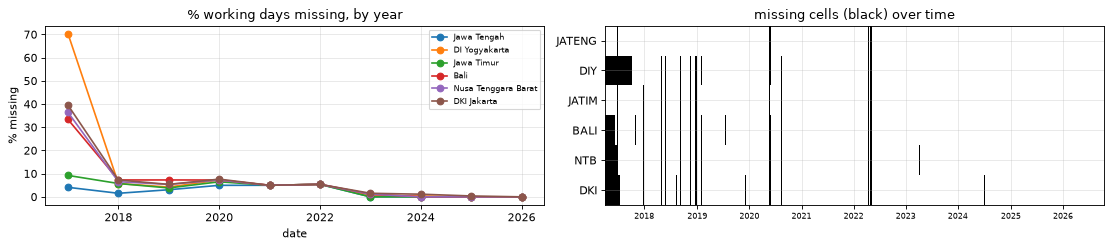

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2))
P_raw.isna().groupby(P_raw.index.year).mean().mul(100).plot(ax=ax[0], marker="o")
ax[0].set(title="% working days missing, by year", ylabel="% missing"); ax[0].legend(fontsize=7)
ax[1].imshow(P_raw.isna().T.values, aspect="auto", interpolation="nearest", cmap="Greys")
ax[1].set_yticks(range(6)); ax[1].set_yticklabels([SHORT[p] for p in PROVINCES])
jan = [i for i, d in enumerate(P_raw.index) if d.month == 1 and d.day <= 7 and d.dayofweek == 0]
ax[1].set_xticks(jan); ax[1].set_xticklabels([P_raw.index[i].year for i in jan], fontsize=7)
ax[1].set_title("missing cells (black) over time"); plt.show()

**Reading the missingness:**
* Gaps are **short** (longest = 6 working days) and **shared across provinces**. 44 dates have *no* province reporting. Matching them against the holiday calendar confirms they are public holidays and election days, i.e. *market not reported*, **not random measurement failure**.
* Missingness falls sharply after 2022, and the last all-province gap is **17 Aug 2022**. Since then PIHPS has a value even on public holidays, so reporting practice **changed** (most likely carry-forward on non-trading days).
  This is a structural break in the data-generating process, recorded as a limitation.
* Provinces **start on different dates** (Jawa Timur Apr 2017 … DI Yogyakarta Oct 2017). Q1 2017 is almost entirely `"-"` on the server.

Decision: **forward-fill for features only, never fill targets, never interpolate.**

### 3.3 Jumps and outliers

In [8]:
lp_ff_wide = np.log(P_raw.ffill())          # log because shocks are multiplicative
r1 = lp_ff_wide.diff()                      # day-over-day log change
rows = []
for p in PROVINCES:
    s = r1[p].loc[first_valid[p]:].dropna()
    big = s[s.abs() > np.log(1.30)]          # >30% in one working day = candidate outlier
    nxt = r1[p].shift(-1).reindex(big.index)
    # a "blip" = big move immediately reversed by >20% -> the signature of a keying error (or a one-day squeeze)
    blips = ((np.sign(big) != np.sign(nxt)) & (nxt.abs() > np.log(1.20))).sum()
    rows.append({"province": p, "n |1d move| > 30%": len(big), "reversed next day (blips)": int(blips),
                 "largest 1d move %": round(100 * (np.exp(s.abs().max()) - 1), 1), "date": s.abs().idxmax().date()})
pd.DataFrame(rows).set_index("province")

,n |1d move| > 30%,reversed next day (blips),largest 1d move %,date
province,,,,
Jawa Tengah,10,2,63.0,2026-03-25
DI Yogyakarta,22,3,80.0,2026-03-25
Jawa Timur,21,1,54.5,2017-12-18
Bali,25,1,63.4,2020-02-24
Nusa Tenggara Barat,16,1,106.4,2019-06-11
DKI Jakarta,12,1,131.0,2020-05-05


**Outlier decision: keep, do not clip.**
* Large one-day moves (>30%) occur 10-25 times per province in 9 years, and **only 1-3 per province reverse the next day**. The rest persist: they are real regime moves (Lebaran surges, harvest crashes), not keying errors. Spikes are exactly what the stakeholder wants forecast. Winsorising or deleting them would remove the signal and make errors look better than they are.

* The handful of blips could be data errors or genuine one-day squeezes. Without market-level raw reports we can't tell, so they are **kept and listed as a limitation**.
  The ML models learn log changes and are scored with MAPE/MAE (not RMSE alone), which limits the influence of any single blip.

### 3.4 Stale (repeated) values

In [9]:
# share of consecutive reported days with an IDENTICAL Rp value: high values suggest carry-forward / sticky reporting
stale = pd.Series({p: round(100 * (P_raw[p].dropna().diff() == 0).mean(), 1) for p in PROVINCES}, name="% identical to previous report")
stale.to_frame()

,% identical to previous report
Jawa Tengah,3.8
DI Yogyakarta,42.0
Jawa Timur,4.9
Bali,14.5
Nusa Tenggara Barat,16.5
DKI Jakarta,45.4


**New finding.** In **DKI Jakarta (45%)** and **DI Yogyakarta (42%)**, almost half of consecutive reports repeat the exact same value, compared with about 4-5% in Jawa Tengah and Jawa Timur.
For a commodity this volatile, that points to **sticky reporting** (few sampled markets, rounding to Rp 2,500 steps, or carry-forward by the reporter) rather than a genuinely flat market.
It lowers measured volatility in those provinces, which matters for the Jakarta discussion later in the EDA. We add `stale_days` as a feature and record it as a limitation.

### 3.5 Target distribution

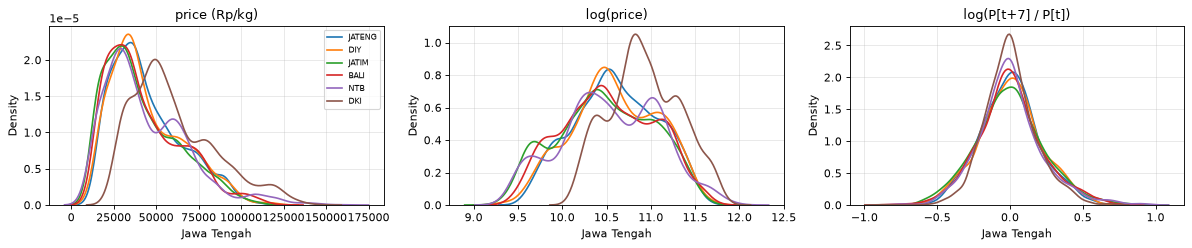

,skew(price),skew(log price),sd 7d log change,excess kurtosis,P(|7d change| > 20%)
region,,,,,
Jawa Tengah,0.779,-0.035,0.206,0.150,0.354
DI Yogyakarta,0.799,-0.073,0.219,0.249,0.346
Jawa Timur,0.816,-0.062,0.237,0.340,0.410
Bali,0.902,0.030,0.224,0.547,0.371
Nusa Tenggara Barat,1.164,-0.046,0.223,1.336,0.335
DKI Jakarta,0.845,0.094,0.177,0.794,0.275


In [10]:
# 7-working-day-ahead log change (what the ML models will predict)
fwd_full = lp_ff_wide.shift(-H) - lp_ff_wide          
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
for p in PROVINCES:
    sns.kdeplot(P_raw[p].dropna(), ax=ax[0], label=SHORT[p])
    sns.kdeplot(np.log(P_raw[p].dropna()), ax=ax[1])
    sns.kdeplot(fwd_full[p].dropna(), ax=ax[2])
ax[0].set(title="price (Rp/kg)"); ax[1].set(title="log(price)"); ax[2].set(title=f"log(P[t+{H}] / P[t])"); ax[0].legend(fontsize=7)
plt.show()
pd.DataFrame({"skew(price)": P_raw.skew(), "skew(log price)": np.log(P_raw).skew(),
              f"sd {H}d log change": fwd_full.std(), "excess kurtosis": fwd_full.kurt(),
              f"P(|{H}d change| > 20%)": (fwd_full.abs() > np.log(1.2)).mean()}).round(3)

**Findings and the modelling choices they drive:**
* Raw price is **right-skewed** (0.8-1.2). **Log price is almost symmetric** (|skew| ≤ 0.1). Shocks are multiplicative (+40% looks the same at Rp 30k or Rp 90k), so **we work in log price** and back-transform.
* The 7-day log change has standard deviation ≈ 0.18-0.24 and **roughly one origin in three sees a move of more than 20%** within 7 working days. This is a hard forecasting problem, and a persistence forecast will be right on average but miss the moves.
* Price **levels** in 2025-26 reach values seldom seen before, and tree models cannot extrapolate beyond the training target range, while **relative changes** are much more stable over time.
  
**Confirmed (Section 15, item 2).** The ML models predict `y = log(P[t+7]) − log(P[t])`, and the price forecast is `P[t]·exp(ŷ)`.

### 3.6 Leakage risks (identified up front, each handled explicitly later)

| Risk | Where | Handling |
|---|---|---|
| Same-day / future weather in features | weather joins | `fetch_weather.py` shifts by `min_lag`=1 and asserts it. Our new weather windows use the same rule plus their own assertion |
| Other provinces' current/future prices | cross-province features | shift by `MIN_LAG` before use, plus a value assertion and a perturbation test |
| Interpolating missing prices | preparation | **forward-fill only** (uses the past), targets never filled |
| Rolling statistics centred on t | features | all windows trailing. Global perturbation test |
| Training labels whose target date lies inside the validation window | CV | purge: train only on rows with `target_date < validation start` |
| Shuffled K-fold on autocorrelated rows | CV | chronological expanding window only, with the size of the K-fold leak quantified |
| **Test data used to choose features** (via EDA) | EDA → features | the test year is locked **before** the EDA that drives feature choices, and those EDA statistics use the development period only |
| Tuning / model selection on test | later, during tuning and evaluation | CV folds only. Test scored once |

## 4. Data preparation

### 4.1 Long panel on the working-day grid, trimmed, forward-filled for features

* Keep the native **Mon-Fri grid**. Holidays stay as rows with NaN, so one row always means one working day and the horizon is exactly 7 rows.
* **Trim** each province to its first valid price instead of back-filling the leading NaN block, which would invent prices.
* `price_ff` = last known price at t (**forward-fill**, past only, so leak-safe). This is used **only for features** and for the "current price" in the back-transform.
  Interpolation is rejected: it would fill a holiday gap using the day *after* it.
* `stale_days` = working days since the last real report, so the model can discount stale information.

In [11]:
grid = pd.bdate_range(P_raw.index.min(), P_raw.index.max())
assert len(grid) == len(P_raw)
long = []
for p in PROVINCES:
    # trim leading NaN block
    s = P_raw[p].loc[first_valid[p]:]                      
    d = pd.DataFrame({"date": s.index, "province": p, "price": s.values})

    # past-only fill (features), never used as a target
    d["price_ff"] = d["price"].ffill()                     
    obs = d["price"].notna()
    
    # 0 on a reported day, 1, 2, ... inside a gap
    d["stale_days"] = d.groupby(obs.cumsum()).cumcount()   
    long.append(d)
df = pd.concat(long, ignore_index=True).sort_values(["province", "date"]).reset_index(drop=True)
df["lp"] = np.log(df["price_ff"])
print(df.groupby("province").agg(rows=("date", "size"), start=("date", "min"), missing_price=("price", lambda s: s.isna().sum())))

                     rows      start  missing_price
province                                           
Bali                 2438 2017-06-14            100
DI Yogyakarta        2355 2017-10-09             77
DKI Jakarta          2420 2017-07-10             95
Jawa Tengah          2489 2017-04-04             59
Jawa Timur           2490 2017-04-03             87
Nusa Tenggara Barat  2425 2017-07-03             86


### 4.2 Target

`target_price` = the **raw** (unfilled) price exactly H = 7 rows ahead. 

Rows whose target day is unreported get NaN and are dropped from training and scoring **identically for every model**, so no model is scored on an invented value.
`target_date` is kept because the CV purge rule needs it.

In [12]:
g = df.groupby("province")
# raw price, NOT forward-filled
df["target_price"] = g["price"].shift(-H)                  
df["target_date"]  = g["date"].shift(-H)
# target: 7-day log change from the last known price
df["y_logret"]     = np.log(df["target_price"]) - df["lp"] 

# Assertion: the target really is the reported price 7 working days later
chk = df.sample(300, random_state=SEED).dropna(subset=["target_price"])
for _, r in chk.iterrows():
    assert r.target_date == r.date + pd.offsets.BDay(H)
    assert P_raw.loc[r.target_date, r.province] == r.target_price
print(f"target alignment verified on {len(chk)} random rows; usable targets per province:")
print(df.groupby("province")["target_price"].count().to_string())

target alignment verified on 291 random rows; usable targets per province:
province
Bali                   2331
DI Yogyakarta          2271
DKI Jakarta            2319
Jawa Tengah            2425
Jawa Timur             2396
Nusa Tenggara Barat    2332


The assertion confirms the target is aligned (no off-by-one, no filled values). The ~3-4% of origins whose target day is a holiday are excluded.

### 4.3 National series (for the cross-region features)

`pihps_prices.csv` also contains the national PIHPS average ("Semua Provinsi"). It is the natural "rest of Indonesia" reference and gets the same `MIN_LAG` treatment as other provinces' prices.

In [13]:
nat = prices_all[prices_all.level == "national"].set_index("date")["price"].reindex(grid).ffill()   # past-only fill
print("national series:", nat.first_valid_index().date(), "->", nat.index.max().date(), "| missing after ffill:", int(nat.isna().sum()))

national series: 2017-04-03 -> 2026-10-16 | missing after ffill: 0


### 4.4 Lock the test year **now**, before any feature-informing EDA

The brief forbids using test data to choose features. Several EDA results below directly choose features: which weather windows to add, whether cross-province signal exists, how wide the holiday windows are.
If those statistics included the test year, test information would leak into the feature set even though no model "saw" the test rows. So the split is fixed here:

* **Test** = origins in the last **250 working days with a usable target** (≈ one year, Oct 2025 → Oct 2026). One year contains a full seasonal and holiday cycle, including Ramadan/Lebaran 2026.
* `DEV_CUTOFF` = the last origin whose **target date** is still before the test period. Every EDA statistic used for a modelling decision is computed on origins ≤ `DEV_CUTOFF`.

In [14]:
dates_with_target = np.sort(df.loc[df.target_price.notna(), "date"].unique())
TEST_START = pd.Timestamp(dates_with_target[-250])
# origin t with t+H < TEST_START
DEV_CUTOFF = grid[grid.get_loc(TEST_START) - H - 1]        
print("TEST_START =", TEST_START.date(), "| DEV_CUTOFF (last dev origin, target before test) =", DEV_CUTOFF.date())

TEST_START = 2025-10-23 | DEV_CUTOFF (last dev origin, target before test) = 2025-10-13


### 4.5 Wide matrices used by the EDA

`LPw` = forward-filled log price per province on the working-day grid. `FWD` = realised 7-day log change, **masked to the development period** so feature-informing EDA cannot see the test year.

In [15]:
LPw = df.pivot(index="date", columns="province", values="lp")[PROVINCES].reindex(grid)
# dev-only outcome for EDA
FWD = (LPw.shift(-H) - LPw).loc[:DEV_CUTOFF]                

# dev-period levels (includes the dev targets)
LPw_dev = LPw.loc[:DEV_CUTOFF + pd.offsets.BDay(H)]         
print(FWD.shape, LPw_dev.index.max().date())

(2226, 6) 2025-10-22


### 4.6 Holiday calendar

**Method.** Ramadan start (1 Ramadan), Idul Fitri/Lebaran (1 Syawal) and Idul Adha (10 Dzulhijjah) move about 11 days earlier each Gregorian year. Instead of typing dates from memory, we **convert them with `hijridate`**, which implements the Umm al-Qura calendar.

**Caveat.** Indonesia's official dates come from the Ministry of Religious Affairs' *sidang isbat*, which can differ from Umm al-Qura by about ±1 day (and Muhammadiyah sometimes starts a day earlier).
The comparison column below gives Indonesian government dates **as I recall them from public SKB calendars. They were not re-verified against an official source in this session.** With feature windows 1-3 weeks wide and a 7-day horizon, a 1-day difference is immaterial.

Christmas (25 Dec) and New Year are fixed dates. **Chinese New Year (Imlek)** dates are hard-coded (no lunisolar converter is in the venv), but unlike the Hijri dates above, Imlek isn't sighting-dependent or region-disputed. it's a fixed astronomical rule (the second new moon after the winter solstice, with leap-month exceptions), so any reputable calendar source agrees to the day. All 12 hard-coded dates (2016-2027) were cross-checked against (vclock.com)[vclock.com], Herong Yang's Chinese calendar archive, USC US-China Institute, and a holiday-API table (2020-2029) from independent sources, exact agreement on every year.

In [16]:
def hijri_to_greg(hy, hm, hd):
    g_ = Hijri(hy, hm, hd).to_gregorian(); return pd.Timestamp(g_.year, g_.month, g_.day)

# Hijri years 1437-1449 cover 2016-2028: one year of margin either side so "days to next/since last" never runs off the table
HOL = pd.DataFrame([{"hijri_year": hy, "ramadan_start": hijri_to_greg(hy, 9, 1),
                     "idul_fitri": hijri_to_greg(hy, 10, 1), "idul_adha": hijri_to_greg(hy, 12, 10)} for hy in range(1437, 1450)])
IMLEK = pd.to_datetime(["2016-02-08", "2017-01-28", "2018-02-16", "2019-02-05", "2020-01-25", "2021-02-12", "2022-02-01",
                        "2023-01-22", "2024-02-10", "2025-01-29", "2026-02-17", "2027-02-06"])
# verified against vclock.com, Herong Yang's Chinese calendar archive, USC US-China Institute, and a holiday-API
# table (2020-2029): all 12 dates match exactly across these independent sources
CHRISTMAS = pd.to_datetime([f"{y}-12-25" for y in range(2016, 2028)])
_h = HOL[HOL.idul_fitri.dt.year.between(2017, 2026)]
_h.set_index(_h.idul_fitri.dt.year.rename("year")).drop(columns="hijri_year")

,ramadan_start,idul_fitri,idul_adha
year,,,
2017,2017-05-27,2017-06-25,2017-09-01
2018,2018-05-16,2018-06-15,2018-08-21
2019,2019-05-06,2019-06-04,2019-08-11
2020,2020-04-24,2020-05-24,2020-07-31
2021,2021-04-13,2021-05-13,2021-07-20
2022,2022-04-02,2022-05-02,2022-07-09
2023,2023-03-23,2023-04-21,2023-06-28
2024,2024-03-11,2024-04-10,2024-06-16
2025,2025-03-01,2025-03-30,2025-06-06


Next, an honesty check on the converter: how far are its Umm al-Qura dates from the dates Indonesia actually observed? A difference of 0-1 days is acceptable for windows that are weeks wide. Larger differences would mean the calendar features are mistimed.

In [17]:
# Comparison with Indonesian-government dates (recalled from SKB calendars)
RECALLED_ID = {2017: ("2017-05-27", "2017-06-25", "2017-09-01"), 2018: ("2018-05-17", "2018-06-15", "2018-08-22"),
               2019: ("2019-05-06", "2019-06-05", "2019-08-11"), 2020: ("2020-04-24", "2020-05-24", "2020-07-31"),
               2021: ("2021-04-13", "2021-05-13", "2021-07-20"), 2022: ("2022-04-03", "2022-05-02", "2022-07-10"),
               2023: ("2023-03-23", "2023-04-22", "2023-06-29"), 2024: ("2024-03-12", "2024-04-10", "2024-06-17"),
               2025: ("2025-03-01", "2025-03-31", "2025-06-06")}
cmp = HOL[HOL.idul_fitri.dt.year.isin(RECALLED_ID)].copy(); cmp["year"] = cmp.idul_fitri.dt.year
for i, k in enumerate(["ramadan_start", "idul_fitri", "idul_adha"]):
    cmp[f"Δdays {k}"] = [(v - pd.Timestamp(RECALLED_ID[y][i])).days for y, v in zip(cmp.year, cmp[k])]
cmp.set_index("year")[[c for c in cmp.columns if c.startswith("Δ")]].T

year,2017,2018,2019,2020,2021,2022,2023,2024,2025
Δdays ramadan_start,0,-1,0,0,0,-1,0,-1,0
Δdays idul_fitri,0,0,-1,0,0,0,-1,0,-1
Δdays idul_adha,0,-1,0,0,0,-1,-1,-1,0


The converted dates match the recalled Indonesian dates **exactly or within 1 day** in every year. The Umm al-Qura date is the same or 1 day earlier, the usual pattern. That is good enough for windows measured in weeks.

**Cross-check against the data:** if the 44 "no province reported" dates (Section 3.2) are market holidays, most should fall on a holiday in this calendar or on a fixed national holiday.

In [18]:
FIXED_NATIONAL = {(1, 1), (5, 1), (6, 1), (8, 17), (12, 24), (12, 25), (12, 31)}   # New Year, Labour, Pancasila, Independence, Christmas
def holiday_tag(d):
    if any(-4 <= (d - f).days <= 7 for f in HOL.idul_fitri): return "Lebaran week (-4..+7 d)"
    if any(abs((d - a).days) <= 1 for a in HOL.idul_adha):    return "Idul Adha"
    if any(abs((d - i).days) <= 1 for i in IMLEK):            return "Imlek"
    if (d.month, d.day) in FIXED_NATIONAL:                     return "fixed national holiday"
    return "other"
tags = pd.Series({d: holiday_tag(d) for d in all_nan[all_nan].index})
print(tags.value_counts().to_string())
print("\n'other' dates:", [d.strftime("%Y-%m-%d") for d in tags[tags == "other"].index])

other                      16
Lebaran week (-4..+7 d)    14
fixed national holiday     10
Idul Adha                   2
Imlek                       2

'other' dates: ['2018-06-27', '2019-03-07', '2019-04-03', '2019-04-17', '2020-05-07', '2020-08-20', '2020-12-09', '2021-03-11', '2021-04-02', '2021-05-26', '2021-10-20', '2022-02-28', '2022-03-03', '2022-04-15', '2022-05-16', '2022-05-26']


28 of the 44 all-province gaps match Lebaran week, Idul Adha, Imlek or a fixed national holiday. The 16 "other" dates are, **on inspection (from memory, not verified here)**, also recognisable public holidays or election days: Nyepi, Isra Mi'raj, Waisak, Good Friday, Ascension Day, Islamic New Year, Maulid, and the 2019 general election (17 Apr 2019) and regional elections (27 Jun 2018, 9 Dec 2020).
This supports both the calendar and the Section 3.2 reading that the gaps are *market closures*.

## 5. Exploratory data analysis

The EDA is weighted toward what moves forecast accuracy: price-series structure (trend, seasonality, autocorrelation, spikes), which weather windows carry signal, and cross-province dynamics. 

The secondary features (Solar, holidays) get proportionate space.
Section 5.1 shows the full history for context. Every statistic that **feeds a modelling decision** uses the development period only (Section 4.4).

### 5.1 Price history per province

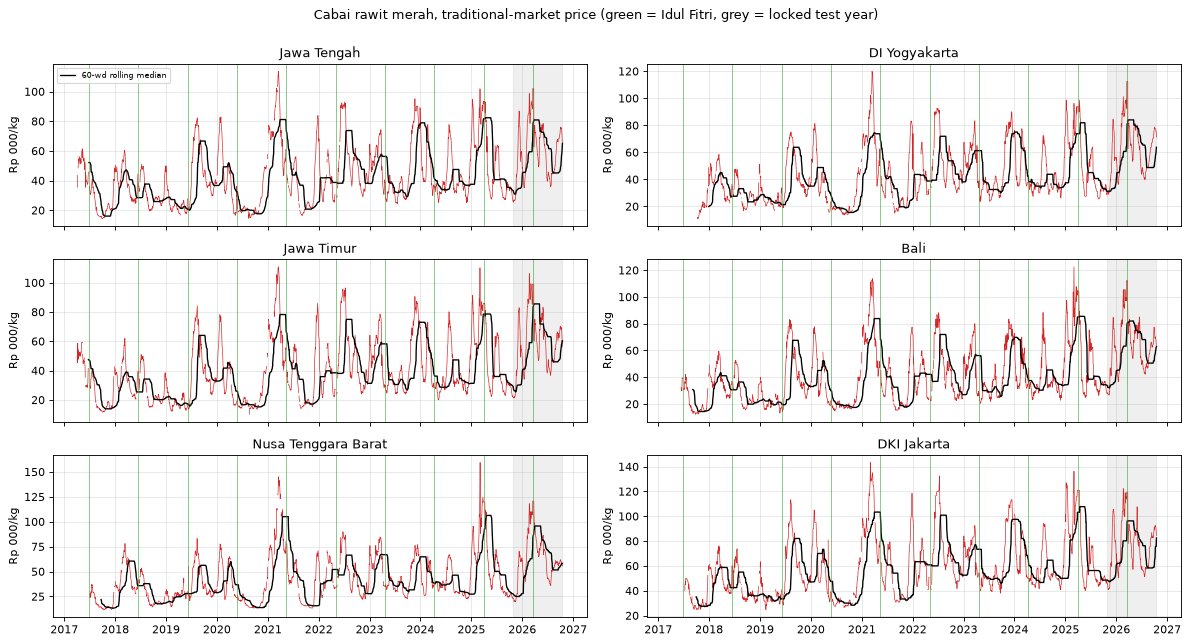

In [19]:
# Full history on purpose (context only, no statistic is computed here); test year shaded so the reader knows what is held out
LEB = HOL.idul_fitri[(HOL.idul_fitri >= grid[0]) & (HOL.idul_fitri <= grid[-1])]
fig, axes = plt.subplots(3, 2, figsize=(15, 8), sharex=True)
for ax, p in zip(axes.flat, PROVINCES):
    s = df[df.province == p].set_index("date")
    ax.plot(s.index, s.price / 1000, lw=0.6, color="tab:red")
    ax.plot(s.index, s.price_ff.rolling(60).median() / 1000, lw=1.2, color="k", label="60-wd rolling median")
    for d in LEB: ax.axvline(d, color="tab:green", lw=0.8, alpha=0.6)
    ax.axvspan(TEST_START, grid[-1], color="grey", alpha=0.12)
    ax.set_title(p); ax.set_ylabel("Rp 000/kg")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Cabai rawit merah, traditional-market price (green = Idul Fitri, grey = locked test year)", y=1.0); plt.show()

* Prices show **recurring multi-month cycles with sharp spikes**. Many peaks fall in the **rainy season (Dec-Mar)**, and in recent years, as Ramadan has moved earlier into that season, also **just before Lebaran**. Troughs tend to come mid-year at dry-season harvest.
* Provinces **move together at low frequency**. How synchronised their *short-term* moves are, and who leads, is examined later in the EDA.
* Levels drift upward and the test-year (grey) peaks are among the highest in the record. That reinforces the Section 3.5 choice to model relative changes.

### 5.2 Trend and seasonality: STL decomposition

STL runs on **weekly-mean log price** with a 52-week period. Weekly aggregation removes reporting noise and holiday gaps, and the robust fit keeps single spikes from bending the seasonal shape.
Strength measures (Hyndman): $F_T = \max\left(0,\ 1 - \dfrac{\mathrm{Var}(R)}{\mathrm{Var}(T+R)}\right)$, $F_S = \max\left(0,\ 1 - \dfrac{\mathrm{Var}(R)}{\mathrm{Var}(S+R)}\right)$. Development period only.

In [20]:
W = np.log(P_raw.loc[:DEV_CUTOFF].resample("W").mean()).interpolate(limit=3)   # EDA-only smoothing; never used for modelling
stl_res, strength = {}, []
for p in PROVINCES:
    w = W[p].loc[W[p].first_valid_index():].dropna()
    res = STL(w, period=52, robust=True).fit(); stl_res[p] = res
    vr = np.var(res.resid)
    prof = res.seasonal.groupby(res.seasonal.index.isocalendar().week).mean()
    strength.append({"province": p, "trend strength F_T": max(0, 1 - vr / np.var(res.trend + res.resid)),
                     "seasonal strength F_S": max(0, 1 - vr / np.var(res.seasonal + res.resid)),
                     "seasonal amplitude (log, max-min)": prof.max() - prof.min()})
strength = pd.DataFrame(strength).set_index("province").round(3); strength

,trend strength F_T,seasonal strength F_S,"seasonal amplitude (log, max-min)"
province,,,
Jawa Tengah,0.202,0.299,0.968
DI Yogyakarta,0.249,0.311,0.938
Jawa Timur,0.214,0.282,1.035
Bali,0.200,0.263,1.121
Nusa Tenggara Barat,0.194,0.322,1.376
DKI Jakarta,0.244,0.228,0.847


Plot of the decomposition for one large producer province (Jawa Timur), and the average seasonal profile of all six provinces on one axis. Do the provinces share a seasonal shape? If so, one pooled model with shared calendar terms is reasonable.

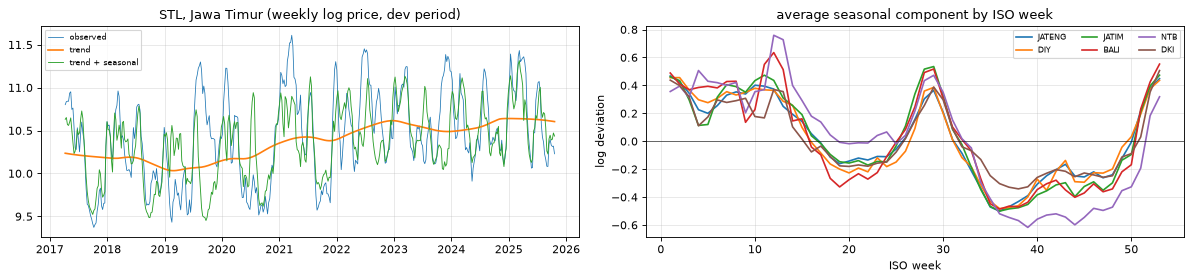

In [21]:
# Jawa Timur shown in detail because it is the largest producer
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
r = stl_res["Jawa Timur"]
ax[0].plot(r.observed, lw=.7, label="observed"); ax[0].plot(r.trend, lw=1.5, label="trend"); ax[0].plot(r.trend + r.seasonal, lw=.8, label="trend + seasonal")
ax[0].legend(fontsize=7); ax[0].set_title("STL, Jawa Timur (weekly log price, dev period)")
for p in PROVINCES:
    s = stl_res[p].seasonal; prof = s.groupby(s.index.isocalendar().week).mean()
    ax[1].plot(prof.index, prof.values, label=SHORT[p])
ax[1].axhline(0, color="k", lw=.5); ax[1].set(title="average seasonal component by ISO week", xlabel="ISO week", ylabel="log deviation"); ax[1].legend(fontsize=7, ncol=3)
plt.show()

* **Both strengths are only moderate** (trend ≈ 0.19-0.25, seasonal ≈ 0.23-0.32). Even at weekly resolution, a large share of variance is irregular (the spikes), and neither a smooth trend nor a fixed annual pattern explains most of the series.
* The **seasonal shape is shared** across provinces: above trend in roughly weeks 1-15 and around week 50 (rainy season, plus Ramadan/Lebaran in recent years), below trend mid-year (dry-season harvest).
  The average seasonal swing is large (0.85-1.4 in log units peak to trough, i.e. roughly a doubling), but year-to-year timing varies, which is why the strength measure stays moderate.
* Implications: (1) a **seasonal-naive** baseline that copies last year should be weak; (2) Ramadan moves about 11 days per year, so a fixed week-of-year pattern blurs the holiday effect, which motivates **explicit holiday-distance features** alongside week-of-year terms.

### 5.3 Autocorrelation and stationarity

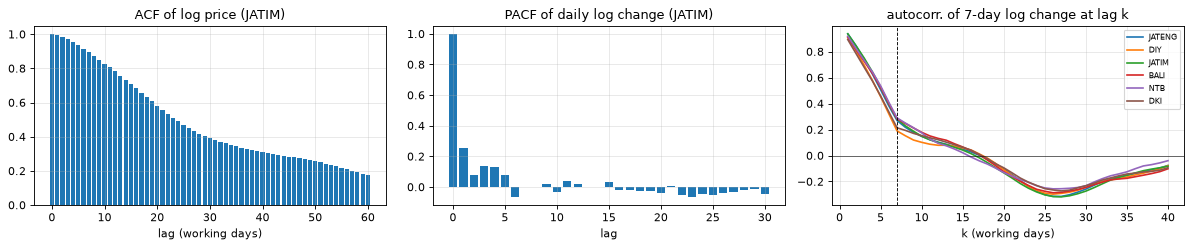

In [22]:
# ACF of the level -> persistence; PACF of daily changes -> AR/MA order hints; ACF of 7-day changes -> momentum vs reversion at our horizon
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
s = LPw_dev["Jawa Timur"].dropna()
ax[0].bar(range(61), acf(s, nlags=60)); ax[0].set(title="ACF of log price (JATIM)", xlabel="lag (working days)")
ax[1].bar(range(31), pacf(s.diff().dropna(), nlags=30)); ax[1].set(title="PACF of daily log change (JATIM)", xlabel="lag")
for p in PROVINCES:
    r7 = LPw_dev[p] - LPw_dev[p].shift(H)
    ax[2].plot(range(1, 41), [r7.autocorr(k) for k in range(1, 41)], label=SHORT[p])
ax[2].axvline(H, color="k", ls="--", lw=.8); ax[2].axhline(0, color="k", lw=.5)
ax[2].set(title="autocorr. of 7-day log change at lag k", xlabel="k (working days)"); ax[2].legend(fontsize=7)
plt.show()

Formal stationarity test (ADF) on the log level and its first difference, plus the statistic that matters most for a 7-day forecast: does the past 7-day change predict the next 7-day change (momentum, positive) or reverse it (mean reversion, negative)?

In [23]:
adf = []
for p in PROVINCES:
    s = LPw_dev[p].dropna()
    adf.append({"province": p, "ADF p-value (log level)": adfuller(s, autolag="AIC")[1],
                "ADF p-value (1st diff)": adfuller(s.diff().dropna(), autolag="AIC")[1],
                # momentum vs mean reversion AT OUR HORIZON: corr(past 7-day change, next 7-day change)
                "corr(past 7d chg, next 7d chg)": s.diff(H).corr(s.shift(-H) - s)})
pd.DataFrame(adf).set_index("province").round(4)

,ADF p-value (log level),ADF p-value (1st diff),"corr(past 7d chg, next 7d chg)"
province,,,
Jawa Tengah,0.0009,0.0,0.2690
DI Yogyakarta,0.0002,0.0,0.1892
Jawa Timur,0.0000,0.0,0.2822
Bali,0.0000,0.0,0.2824
Nusa Tenggara Barat,0.0000,0.0,0.2893
DKI Jakarta,0.0000,0.0,0.2130


* Log price is **highly persistent**: the ACF stays high for weeks. But the **ADF test rejects a unit root even in levels** (p < 0.001 in all provinces).
  So over the 9-year span chili prices **mean-revert** (spikes end, supply responds), even though they wander far from the mean for months. That is consistent with a commodity whose supply responds to price within a few crop cycles.
* At **our horizon**, the past 7-day change is **positively** correlated with the next 7-day change (+0.19 to +0.29 in every province). That is **momentum**: spikes and crashes build over several weeks rather than reversing immediately. The ACF of 7-day changes (right panel) turns negative only beyond about 20 working days.
* Consequences for modelling:
  * the features need both **short momentum** (`ret_*`) and **distance from longer-run levels** (`dev_*`, mean reversion);
  * ARIMA with `d=1` is a reasonable default for a 7-step forecast of a near-unit-root series, but since ADF rejects a unit root, `d=0` (with a constant) is **added to the ARIMA tuning grid** instead of assumed away;
  * the PACF of daily changes has a few significant short lags, so low-order AR/MA terms are justified.

### 5.4 Spike characterisation (how often, how big, how long)

A **spike episode** = a run of ≥ 5 working days in which price exceeds **1.3 × its trailing 250-working-day median**. The median is shifted by 1 day, so the definition never looks ahead.

In [24]:
ep_rows = []
for p in PROVINCES:
    s = np.exp(LPw_dev[p]).dropna()
    base = s.rolling(250, min_periods=120).median().shift(1)
    on = (s > 1.3 * base).fillna(False)
    rid = (on != on.shift()).cumsum()
    for _, g_ in s[on].groupby(rid[on]):
        ep_rows.append({"province": p, "start": g_.index[0], "days": len(g_), "peak_ratio": (g_ / base.loc[g_.index]).max()})
EP = pd.DataFrame(ep_rows); EP = EP[EP.days >= 5]          # drop 1-4 day blips: we care about persistent regimes
spk = EP.groupby("province").agg(n_episodes=("days", "size"), median_days=("days", "median"), max_days=("days", "max"),
                                 median_peak_x=("peak_ratio", "median"), max_peak_x=("peak_ratio", "max")).round(2)
spk["% of days in spike"] = [round(100 * EP[EP.province == p].days.sum() / LPw_dev[p].notna().sum(), 1) for p in spk.index]
print("episode start month (all provinces):", EP.start.dt.month.value_counts().sort_index().to_dict())
spk

episode start month (all provinces): {1: 8, 2: 14, 3: 11, 5: 7, 6: 13, 7: 12, 9: 3, 10: 8, 11: 6, 12: 25}


,n_episodes,median_days,max_days,median_peak_x,max_peak_x,% of days in spike
province,,,,,,
Bali,17,22.0,124,1.98,5.30,32.2
DI Yogyakarta,16,20.5,135,1.96,5.93,28.5
DKI Jakarta,14,28.0,126,1.99,4.05,28.9
Jawa Tengah,19,22.0,127,1.79,5.05,29.0
Jawa Timur,22,18.0,126,1.87,5.51,31.6
Nusa Tenggara Barat,19,27.0,127,1.80,6.13,33.0


* Spikes are **common and persistent**: 14-22 episodes per province in the development period, **median length about one month** (18-28 working days), the longest about 6 months. **About 29-33% of all days** are in a spike state.
* Typical peaks are **≈ 1.8-2.0× the trailing-year median**, and the most extreme reach 4-6×.
* Episodes start most often in **December** (25 of 107, the onset of the rainy season), then Feb-Mar and Jun-Jul. Very few start in Sep-Nov. This fits the weather story.
* Persistence of about a month plus 7-day momentum means that **once a spike is under way, recent changes are informative**. It also means neighbouring days are near-duplicates, which is why shuffled K-fold would leak.

### 5.5 DKI Jakarta sanity check: does the deliberately added province behave differently?

**Background.** Provinces were screened from all 34 on two statistical criteria: **≥ 93% working-day coverage** and **meaningful volatility (CV)** so the series isn't flat. Five passed.
**DKI Jakarta was added afterwards on a different basis.** It clears the coverage bar (95.9%) but has the **lowest CV of the six** (40.6% vs 46.3-55.6%), so on volatility alone it would not have been picked.
The group included it because Jakarta, the capital and the largest consumption centre on the most densely populated island (Java), is a plausible **demand-anchor market** worth forecasting in its own right.
This is a **deliberate deviation from the screening rule**. The checks below ask whether Jakarta behaves *structurally* differently, which would matter for pooling it into one model with the others.

In [25]:
# Structural comparison on dev data: volatility, short memory, staleness, seasonality and co-movement with the other provinces
R5 = LPw_dev.diff(5)
rows = []
for p in PROVINCES:
    s = LPw_dev[p].dropna(); d1 = s.diff()
    others = [q for q in PROVINCES if q != p]
    rows.append({"province": p, "CV %": float(quality.set_index("region").loc[p, "cv_pct"]),
                 "sd daily chg": d1.std(), "sd 7d chg": s.diff(H).std(), "ACF(1) daily chg": d1.autocorr(1),
                 "stale %": stale[p], "seasonal strength": strength.loc[p, "seasonal strength F_S"],
                 "mean corr of 5d chg with others": R5[others].corrwith(R5[p]).mean()})
pd.DataFrame(rows).set_index("province").round(3)

,CV %,sd daily chg,sd 7d chg,ACF(1) daily chg,stale %,seasonal strength,mean corr of 5d chg with others
province,,,,,,,
Jawa Tengah,46.3,0.053,0.206,0.256,3.8,0.299,0.831
DI Yogyakarta,47.8,0.068,0.221,0.063,42.0,0.311,0.770
Jawa Timur,52.2,0.062,0.238,0.255,4.9,0.282,0.828
Bali,51.6,0.070,0.226,0.084,14.5,0.263,0.782
Nusa Tenggara Barat,55.6,0.066,0.225,0.115,16.5,0.322,0.725
DKI Jakarta,40.6,0.059,0.176,0.026,45.4,0.228,0.745


Visual check of the same question: rebase everything to 1 on 2019-01-02 and overlay Jakarta on the Java producer provinces. A structurally different market would show a different cycle, not only a smoother one.

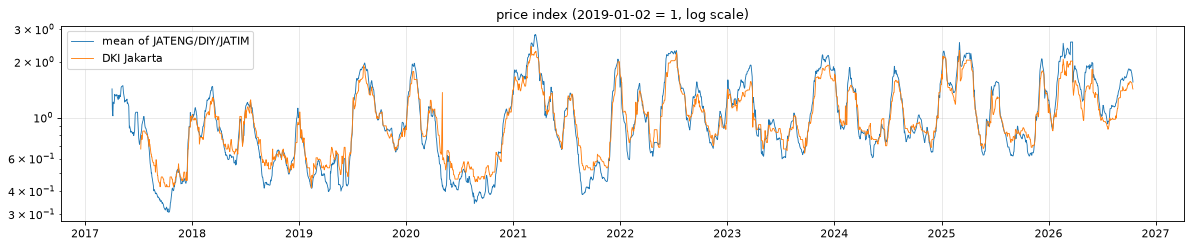

In [26]:
idx = np.exp(LPw - LPw.loc["2019-01-02"])                 # price index, 2019-01-02 = 1, so levels are comparable
fig, ax = plt.subplots(figsize=(15, 3.2))
ax.plot(idx.index, idx[["Jawa Tengah", "DI Yogyakarta", "Jawa Timur"]].mean(axis=1), lw=.8, label="mean of JATENG/DIY/JATIM")
ax.plot(idx.index, idx["DKI Jakarta"], lw=.8, label="DKI Jakarta")
ax.set_yscale("log"); ax.set_title("price index (2019-01-02 = 1, log scale)"); ax.legend(); plt.show()

**Verdict on Jakarta (for the group to confirm):**
* Jakarta follows **the same low-frequency cycle** as the Java producer provinces (index plot), and its 5-day changes correlate with the other provinces' at 0.75, inside the 0.73-0.83 range of the others.
  It is **not a structurally different market**, so pooling it into one global model with a province indicator is reasonable.
* It is **smoother and slightly less seasonal**: lowest 7-day volatility (0.18 vs 0.21-0.24), the weakest seasonal strength (0.23 vs 0.26-0.32) and the lowest day-to-day autocorrelation of changes (0.03).
  Part of that is the **stale-reporting artefact** from Section 3.4 (45% repeated values, like DIY, which also has low ACF(1)). So Jakarta's low CV is partly a **measurement property**, not only a market property.
* Practical implication: report per-province errors. Jakarta should be **easier in MAPE terms** (smaller moves), so the macro-average must not be read as "the model works equally well everywhere".


### 5.6 Cross-province lead/lag

**Mechanism (plausible, not proven): regional supply redistribution / arbitrage.** A shortage in a producer province raises its price first, traders then pull supply from linked markets, and those prices follow with a lag.
If so, **another province's recent change should predict our province's next 7 days**, possibly better than our own recent change.

Below: Spearman correlation between province *j*'s 5-day log change ending **t − MIN_LAG** and province *i*'s change from t to t+7 (development period).

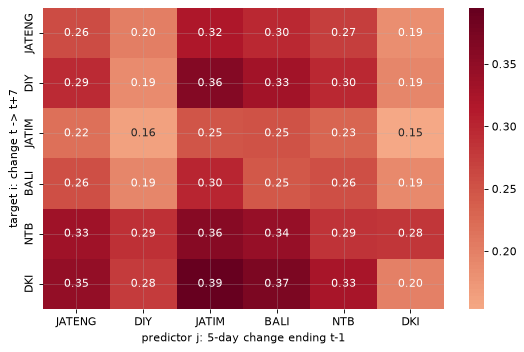

best single predictor for each target province: {'JATENG': 'JATIM', 'DIY': 'JATIM', 'JATIM': 'BALI', 'BALI': 'JATIM', 'NTB': 'JATIM', 'DKI': 'JATIM'}


In [27]:
lag5 = (LPw - LPw.shift(5)).shift(MIN_LAG).loc[:DEV_CUTOFF]          # predictor already lagged, exactly as the feature will be
Mx = pd.DataFrame({j: [stats.spearmanr(lag5[j], FWD[i], nan_policy="omit")[0] for i in PROVINCES] for j in PROVINCES}, index=PROVINCES)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(Mx.rename(index=SHORT, columns=SHORT), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set(xlabel="predictor j: 5-day change ending t-1", ylabel="target i: change t -> t+7"); plt.show()
print("best single predictor for each target province:", {SHORT[i]: SHORT[Mx.loc[i].idxmax()] for i in PROVINCES})

* All correlations are **positive** (0.15-0.39). Momentum is shared: when chili is rising anywhere, it tends to keep rising everywhere over the next week.
* The striking pattern is that **Jawa Timur's recent change is the best single predictor for every other province** (for Jawa Timur itself, Bali's is marginally best), often clearly better than the province's own past change (e.g. DKI: JATIM 0.39 vs own 0.20; DIY: JATIM 0.36 vs own 0.19).
  Jawa Timur is Indonesia's largest chili-producing province, so this fits a **"producer leads, consumer follows"** pattern. It is also exactly the information a single-series model (ETS/ARIMA) cannot use.
* Caveats: overlapping 7-day windows make the effective sample much smaller than the row count, and a common national shock reported slightly earlier in one province would produce the same picture. This is evidence for **predictive** value, not for the arbitrage mechanism itself.
  A later CV ablation tests whether the signal survives once own-price features are in the model.

### 5.7 Weather: which lag windows actually carry signal?

`fetch_weather.py` uses **fixed windows** (7/14/30/60/90 days ending t−1, point lags 1-30 days). Rather than trusting them, we scan a grid of **window length w × extra lag L**: the rain total over `[t−L−w+1, t−L]` (with L ≥ `MIN_LAG`). It is correlated with two outcomes:
* **(a)** the forward 7-day log change (exactly what the ML models predict);
* **(b)** the *level deviation* at t+7: log price minus its trailing-250-day median (does weather mark a *high-price phase*?).

Spearman ρ is computed per province and averaged, using `weather_daily_raw.csv` (EDA-only raw file) on development-period origins only.

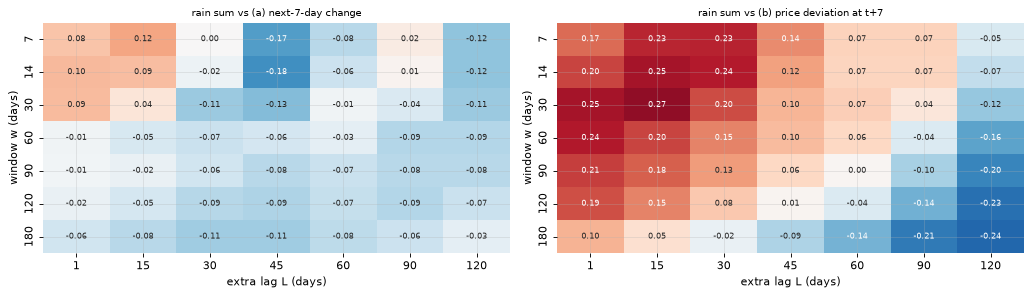

In [28]:
WIN  = [7, 14, 30, 60, 90, 120, 180]        # from one week to a full growing season
LAGS = [1, 15, 30, 45, 60, 90, 120]         # from "yesterday" to ~4 months (chili: transplant -> first harvest ~ 2.5-3 months)
med250 = LPw.rolling(250, min_periods=120).median().shift(1)
DEV_T7 = (LPw - med250).shift(-H).loc[:DEV_CUTOFF]           # outcome (b), dev-only

def wx_window(var, prov, w, L):
    # rolling on CALENDAR days (weekends included, like fetch_weather.py), then shift L days, then onto working days
    s = wx_raw[wx_raw.province == prov].set_index("date")[var].asfreq("D")
    agg = s.rolling(w, min_periods=w).sum() if var in ("precipitation_sum", "et0_fao_evapotranspiration") else s.rolling(w, min_periods=w).mean()
    return agg.shift(L).reindex(grid).loc[:DEV_CUTOFF]

def ccf_grid(var, outcome):
    out = np.zeros((len(WIN), len(LAGS)))
    for p in PROVINCES:
        for i, w in enumerate(WIN):
            for j, L in enumerate(LAGS):
                out[i, j] += stats.spearmanr(wx_window(var, p, w, L), outcome[p], nan_policy="omit")[0] / len(PROVINCES)
    return pd.DataFrame(out, index=WIN, columns=LAGS).rename_axis(index="window w (days)", columns="extra lag L (days)")

cc_rain_a, cc_rain_b = ccf_grid("precipitation_sum", FWD), ccf_grid("precipitation_sum", DEV_T7)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, m, t in zip(axes, [cc_rain_a, cc_rain_b], ["rain sum vs (a) next-7-day change", "rain sum vs (b) price deviation at t+7"]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.3, vmax=.3, ax=ax, cbar=False, annot_kws={"size": 7}); ax.set_title(t, fontsize=9)
plt.show()

**What the rain scan says:**
* **(b) price regime.** The strongest positive association is with **2-4 weeks of rain ending about 2 weeks ago** (w = 14-30, L = 1-30: ρ up to ≈ 0.27). Recent wet spells go with high prices, plausibly through damaged flowers and fruit, fungal disease, and disrupted picking and transport.
  Long windows with long lags (w ≥ 90, L ≥ 90) turn **negative** (down to ≈ −0.24). That is the seasonal phase: heavy rain 4-6 months ago means we are now in the following dry season. It is shared seasonality, not a delayed crop effect, but it is still predictive information.
* **(a) next-week change.** Weaker overall. Recent rain (w = 7-30, L = 1-15) gives ρ ≈ +0.1, and rain **about 6-7 weeks ago** (w = 7-14, L = 45) gives ρ ≈ −0.18. One plausible reading: plantings that got through a wet spell come to harvest weeks later and push prices down.
* **Verdict on `fetch_weather.py`'s fixed windows:** the 7-30-day windows ending t−1 sit close to the best region for (b), so they are **well chosen**. The 60/90-day windows ending t−1 are weaker. The script has **no lagged windows**, which is where the next-week (a) signal and the strongest (b) cells are.
  Add a few **data-driven lagged windows**, picked programmatically below from the strongest dev-period cells not already covered. **Confirmed, kept (Section 15, item 6):** the ablation later showed they help in all 3 model families.
* Caveat: rain and price share an annual cycle, and Ramadan has moved into the rainy season during 2017-2026. These correlations are **for feature screening only**. They are not evidence of a weather → price effect. With autocorrelated data, |ρ| below about 0.1 is hard to tell apart from zero.

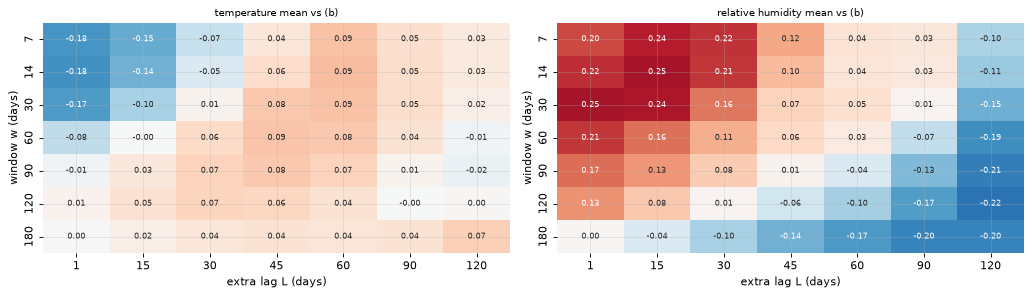

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
cc_t_b, cc_h_b = ccf_grid("temperature_2m_mean", DEV_T7), ccf_grid("relative_humidity_2m_mean", DEV_T7)
for ax, m, t in zip(axes, [cc_t_b, cc_h_b], ["temperature mean vs (b)", "relative humidity mean vs (b)"]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.3, vmax=.3, ax=ax, cbar=False, annot_kws={"size": 7}); ax.set_title(t, fontsize=9)
plt.show()

Temperature (negative at short windows: cool means cloudy and wet) and humidity (positive, almost a copy of the rain map) give **the same picture as rain with the sign flipped or kept**. They are largely redundant with rainfall, so no extra temperature/humidity windows are added beyond the existing ones.

In [30]:
# Programmatic, dev-only choice of extra lagged rain windows: strongest cells NOT already produced by fetch_weather.py
existing = {(w, 1) for w in (7, 14, 30, 60, 90)}
def top_cells(m, k):
    st = m.stack().rename("rho").reset_index(); st.columns = ["w", "L", "rho"]
    st = st[[(w, L) not in existing for w, L in zip(st.w, st.L)]]
    return st.reindex(st.rho.abs().sort_values(ascending=False).index).head(k)
pick_b, pick_a = top_cells(cc_rain_b, 3), top_cells(cc_rain_a, 2)
picked = pd.concat([pick_b.assign(outcome="(b) regime"), pick_a.assign(outcome="(a) next-7d change")]).drop_duplicates(["w", "L"])
WX_EXT_SPEC = [(f"rain_sum_{int(w)}d_lag{int(L)}", "precipitation_sum", int(w), int(L) - MIN_LAG, "sum") for w, L in zip(picked.w, picked.L)]
picked.round(3)

,w,L,rho,outcome
15,30,15,0.267,(b) regime
8,14,15,0.250,(b) regime
48,180,120,-0.239,(b) regime
10,14,45,-0.183,(a) next-7d change
3,7,45,-0.169,(a) next-7d change


Five cells were picked: two "recent wet spell" windows (30 d and 14 d ending 15 days ago), one long seasonal-phase window (180 d ending 120 days ago), and two "rain 6-7 weeks ago" windows for the next-week change. These become the **extended rain features** (`wx_ext`) used later in feature engineering. Their names encode the window and the total lag. Because `L` above already includes the `MIN_LAG` day, the builder shifts by `MIN_LAG + (L − MIN_LAG)`.

### 5.8 Extra weather variables: shortwave radiation and ET0

Two variables beyond rain, temperature and humidity are in the panel as an experimental group (`wx_extra`):
* **Shortwave radiation** (sunlight). Low sun plus high humidity is a classic fungal-disease risk combination for chili, and radiation separates "rainy and dark" from "rainy and bright".
* **ET0 (FAO reference evapotranspiration)**. A drought / water-stress proxy that covers the **dry-season** side of supply shortages better than raw temperature and humidity.
* *Windspeed* was considered and **deprioritised**: it is noisier, and storm damage is a threshold event that daily maxima capture poorly.

`fetch_weather.py` now builds them directly into `pihps_red_cayenne_pepper.csv` as **`srad_mean_{7,30}d` and `et0_mean_{7,30}d`**: the same rolling-mean windows ending t−1 as `temp_mean_*` / `rh_mean_*`, with the same `min_lag` shift. So no window needs to be engineered here.
The scan below only asks a narrower question: **do the panel's 7/30-day windows capture the dev-period signal, or does some other (w, L) cell carry clearly more?** If it did, a custom window would be worth keeping on top of the panel columns.

weather accessed: 2026-10-18T08:29:44 | raw missing: {'shortwave_radiation_sum': 0, 'et0_fao_evapotranspiration': 0}


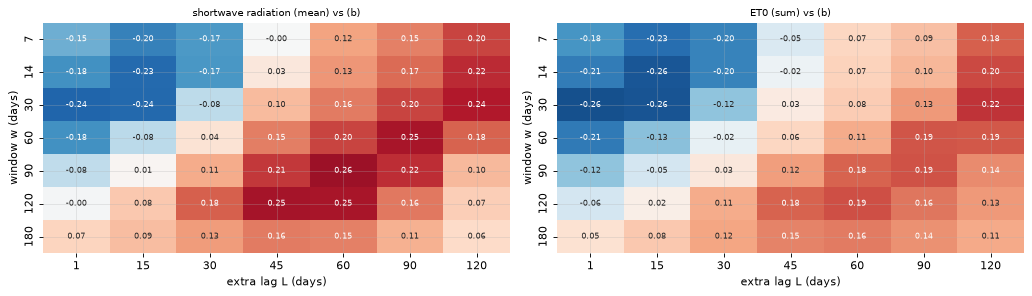

daily corr with precipitation: {'shortwave_radiation_sum': -0.51, 'et0_fao_evapotranspiration': -0.67}


In [31]:
# Same window x lag scan as for rain (Section 5.7), on the raw daily series, outcome (b), dev period only.
# Radiation is averaged and ET0 summed over the window. Spearman rho is scale-free, so on a full window the sum and the mean rank
# identically: the cells w = 7 / 30, L = 1 are therefore exactly the panel columns srad_mean_{7,30}d and et0_mean_{7,30}d.
print("weather accessed:", meta_w["accessed_at"], "| raw missing:",
      wx_raw[["shortwave_radiation_sum", "et0_fao_evapotranspiration"]].isna().sum().to_dict())
cc_rad_b, cc_et0_b = ccf_grid("shortwave_radiation_sum", DEV_T7), ccf_grid("et0_fao_evapotranspiration", DEV_T7)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, m, t in zip(axes, [cc_rad_b, cc_et0_b], ["shortwave radiation (mean) vs (b)", "ET0 (sum) vs (b)"]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.3, vmax=.3, ax=ax, cbar=False, annot_kws={"size": 7}); ax.set_title(t, fontsize=9)
plt.show()
# correlation of the raw daily series with rain: how much NEW information could they add?
print("daily corr with precipitation:", wx_raw[["precipitation_sum", "shortwave_radiation_sum", "et0_fao_evapotranspiration"]].corr(method="spearman").iloc[0, 1:].round(2).to_dict())

* Radiation and ET0 are close to **mirror images of the rain map**: negative at short windows (sunny, high-evaporation weeks go with *lower* prices) and positive at long windows with long lags (the opposite season).
  Their daily series correlate with precipitation at −0.51 (radiation) and −0.67 (ET0), so much of their information is **already carried by the rain features**.

Comparing the panel windows with the strongest cell of each scan:

In [32]:
# Do the panel's default windows (7 / 30 days ending t-1) capture the signal, or would a custom (w, L) cell add something?
# (1) rho of the panel-equivalent cells vs the strongest cell; (2) how much the strongest cell overlaps with the lagged rain
# windows already chosen in Section 5.7 (pooled Spearman over provinces, dev period), i.e. whether it is new information at all.
def pooled_corr(var_a, w_a, L_a, var_b, w_b, L_b):
    return np.nanmean([stats.spearmanr(wx_window(var_a, p, w_a, L_a), wx_window(var_b, p, w_b, L_b), nan_policy="omit")[0] for p in PROVINCES])

rows = []
for short, var, m in [("srad", "shortwave_radiation_sum", cc_rad_b), ("et0", "et0_fao_evapotranspiration", cc_et0_b)]:
    st = m.stack(); w_b, L_b = st.abs().idxmax()
    overlap = {name: pooled_corr(var, w_b, L_b, "precipitation_sum", w, L + MIN_LAG) for name, _, w, L, _ in WX_EXT_SPEC}
    k = max(overlap, key=lambda n: abs(overlap[n]))
    rows.append({"variable": short, "rho panel 7d": m.loc[7, 1], "rho panel 30d": m.loc[30, 1],
                 "strongest cell": f"w={w_b}, L={L_b}", "rho strongest": st.loc[(w_b, L_b)],
                 "most similar wx_ext window": k, "corr with it": overlap[k]})
pd.DataFrame(rows).set_index("variable").round(3)

,rho panel 7d,rho panel 30d,strongest cell,rho strongest,most similar wx_ext window,corr with it
variable,,,,,,
srad,-0.145,-0.241,"w=90, L=60",0.258,rain_sum_180d_lag120,-0.378
et0,-0.176,-0.265,"w=30, L=1",-0.265,rain_sum_30d_lag15,-0.683


* **ET0:** the strongest dev-period cell *is* the panel's `et0_mean_30d` (w = 30, L = 1, ρ = −0.27). Nothing to add.
* **Radiation:** `srad_mean_30d` reaches ρ = −0.24. The strongest cell is a long seasonal-phase window (90 days ending 60 days ago, ρ = +0.26), only marginally stronger in absolute terms, and it overlaps with the seasonal-phase rain window `rain_sum_180d_lag120` already chosen in Section 5.7 (pooled ρ = −0.38).
* **Decision:** the earlier custom radiation/ET0 window selection is **removed**. `wx_extra` is simply the four panel columns, pulled from the panel the same way as the base weather group. The one custom cell that would go beyond them (radiation, 90 d ending 60 d ago) adds at most 0.02 in |ρ| and is partly redundant with an existing rain window, so it does not justify its own engineering step.

**Confirmed, dropped (Section 15, item 6):** the later ablation found `wx_extra` helps only Random Forest, so it is excluded from the final feature set.

### 5.9 Holiday demand: event study around Ramadan, Lebaran, Idul Adha and Christmas

This shows the median log-price path around each event, relative to the level **30 working days before** it, pooled over years and provinces (development period only). The shaded band is the interquartile range.
It answers two questions: is there a pre-holiday pattern worth encoding, and **how wide** should the holiday windows be?

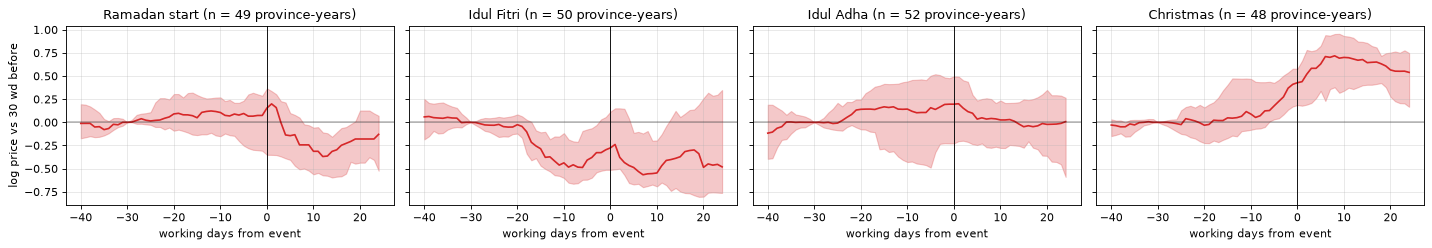

In [33]:
def event_study(dates, before=40, after=25):
    paths = []
    for p in PROVINCES:
        s = LPw_dev[p]
        for d in dates:
            pos = s.index.searchsorted(d)
            if pos - before < 0 or pos + after > len(s): continue          # event too close to either end of the dev period
            seg = s.iloc[pos - before: pos + after].values                 # skip province-years with gaps (series not started yet)
            if len(seg) == before + after and not np.isnan(seg).any(): paths.append(seg - s.iloc[pos - 30])
    return np.array(paths)

EVENTS = {"Ramadan start": HOL.ramadan_start, "Idul Fitri": HOL.idul_fitri, "Idul Adha": HOL.idul_adha, "Christmas": pd.Series(CHRISTMAS)}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.2), sharey=True)
for ax, (k, ds) in zip(axes, EVENTS.items()):
    a = event_study(ds); x = np.arange(-40, 25)
    ax.plot(x, np.median(a, 0), color="tab:red"); ax.fill_between(x, np.percentile(a, 25, 0), np.percentile(a, 75, 0), alpha=.25, color="tab:red")
    ax.axvline(0, color="k", lw=.8); ax.axhline(0, color="k", lw=.4); ax.set(title=f"{k} (n = {len(a)} province-years)", xlabel="working days from event")
axes[0].set_ylabel("log price vs 30 wd before"); plt.show()

**This result contradicts the conventional story, and that matters:**
* The commonly cited "pre-Lebaran demand surge" is **not visible** in this sample for cabai rawit merah. The median path rises only mildly (≈ +0.1-0.2 log) into **Ramadan start**, then **falls during Ramadan**. Relative to 30 working days before Idul Fitri, prices around Lebaran are typically **lower**, not higher (median ≈ −0.3 to −0.5 log).
* The largest event-aligned move is around **Christmas / New Year** (median ≈ +0.5-0.7 log). That coincides with the **December onset of the rainy season**, when most spike episodes start (Section 5.4), so it most likely reflects weather and season rather than Christmas demand. The two cannot be separated with these data.
* Idul Adha shows a small, inconsistent bump.
* Why the Lebaran pattern may be hidden: over 2017-2025 Ramadan moved from **June (dry-season harvest)** to **March (end of the rainy season)**, so each year's holiday falls in a different supply situation, and the bands are very wide. Government market operations before Lebaran may also dampen the surge they are designed to prevent.
  With only about 9 events per holiday, these are descriptive patterns: they **don't** establish the absence of a holiday demand effect.
* Consequence: the holiday features are still built, since the expected effect was the project's top prior hypothesis and the brief requires features to be tested, not assumed. But they are now a **hypothesis to test**, and a later ablation decides.
  The calendar windows below keep the conventional definitions, so this is a fair test of the conventional hypothesis.

## 6. Feature engineering

Every feature at origin *t* must be computable from information available at the **end of working day t**. The groups, and why each is leak-safe:

| Group | Information time | Leak-safety argument |
|---|---|---|
| `own`: own price | ≤ t | the PIHPS day-t price is published on day t. Forward-fill uses past values only |
| `prov`: province indicator | static | fixed category set, nothing estimated |
| `xprov`: cross-province / national | ≤ t − `MIN_LAG` | shift first, then compute. Value assertion plus perturbation test |
| `wx_base`: rain / temperature / humidity | ≤ t − 1 | built and asserted in `fetch_weather.py` |
| `wx_extra`: radiation / ET0 | ≤ t − 1 | built in `fetch_weather.py`, re-derived from the raw series here |
| `wx_ext`: lagged rain windows | ≤ t − `MIN_LAG` − L | calendar-day rolling, then `shift(MIN_LAG + L)`. Assertion included |
| `cal`: calendar / holidays | deterministic | known in advance |
| `solar`: Solar price  | ≤ t | administratively announced, effective same day. As-of join |

### 6.1 Own-price features

In [34]:
def own_price_features(d):
    # All windows are TRAILING (rolling over past rows of the same province). Nothing is centred.
    g_ = d.groupby("province", group_keys=False)
    f = pd.DataFrame(index=d.index)
    f["lp"] = d["lp"]                                          # level: "already very high" -> mean reversion (ADF, Section 5.3)
    for k in (1, 3, 5, 10, 20, 60):                            # momentum at several speeds (7-day momentum found in Section 5.3)
        f[f"ret_{k}"] = d["lp"] - g_["lp"].shift(k)
    for k in (20, 60, 250):                                    # position in the cycle vs 1 month / 1 quarter / 1 year
        f[f"dev_{k}"] = d["lp"] - g_["lp"].transform(lambda s: s.rolling(k, min_periods=k // 2).mean())
    dl = g_["lp"].diff()
    for k in (10, 60):                                         # volatility regime: spikes cluster (Section 5.4)
        f[f"vol_{k}"] = dl.groupby(d["province"]).transform(lambda s: s.rolling(k, min_periods=k // 2).std())
    f["range_20"] = g_["lp"].transform(lambda s: s.rolling(20).max() - s.rolling(20).min())
    # seasonal-naive information offered as FEATURES (not imposed): last year's level and last year's 7-day move
    f["yoy_naive_ret"] = g_["lp"].shift(260 - H) - d["lp"]
    f["ly_fwd_ret"]    = g_["lp"].shift(260 - H) - g_["lp"].shift(260)
    f["stale_days"] = d["stale_days"]                          # how old the "current" price really is (Section 3.4)
    return f

F_own = own_price_features(df); OWN = list(F_own.columns)
print(len(OWN), "own-price features:", OWN)

16 own-price features: ['lp', 'ret_1', 'ret_3', 'ret_5', 'ret_10', 'ret_20', 'ret_60', 'dev_20', 'dev_60', 'dev_250', 'vol_10', 'vol_60', 'range_20', 'yoy_naive_ret', 'ly_fwd_ret', 'stale_days']


16 own-price features covering level, momentum (1 day → 3 months), distance from 1-month/1-quarter/1-year means, volatility, recent range, last year's behaviour and staleness.
The 260-row lags (≈ 1 working year) give the model the seasonal-naive information **as an input it can down-weight**, since Section 5.2 showed a fixed annual pattern is unreliable.

### 6.2 Province indicator

One **global model** across the six provinces gives 6× more spikes and holiday episodes to learn from than six separate models, which matters with only about 9 years of history. A one-hot province indicator lets it learn level and volatility differences (e.g. Jakarta's smoother series, Section 5.5).

In [35]:
F_prov = pd.get_dummies(df["province"].map(SHORT), prefix="prov").astype(float)   # deterministic: no fitting, cannot leak
PROV = list(F_prov.columns); print(PROV)

['prov_BALI', 'prov_DIY', 'prov_DKI', 'prov_JATENG', 'prov_JATIM', 'prov_NTB']


### 6.3 Cross-province and national lagged price features (newly implemented)

This driver was named in the README from the start, but a code search confirmed it was **not implemented anywhere**. It is built here following `fetch_weather.py`'s convention exactly:
**shift each source series by `MIN_LAG` first, then compute features only from the shifted series**, with an explicit leak check.

For province *i* at origin *t*:
* `xp_ret5_<J>` for all six provinces J: J's 5-day log change ending t − `MIN_LAG`. All six are included because Section 5.6 showed **which** province moved matters (Jawa Timur leads).
* `xp_others_ret5`, `xp_others_ret20`: the same for the mean of the **other five** provinces (a regional pressure index).
* `xp_spread_others`: own log price minus the others' mean, both at t − `MIN_LAG`. A province that is expensive relative to its neighbours should attract supply (arbitrage).
* `nat_ret5`, `nat_spread`: the same against the PIHPS national average.

**Causal story (plausible, not established):** regional supply redistribution. A local shortage raises the local price, traders reroute supply, and linked markets follow with a lag.
`MIN_LAG = 1` is deliberately conservative: other provinces' day-t prices are probably published together with our own, but we don't rely on publication timing we haven't verified.

In [36]:
def cross_province_features(d, LP_wide, nat_series, min_lag=MIN_LAG):
    assert min_lag >= 1, "lag 0 would use other provinces' same-day prices"
    S = LP_wide.shift(min_lag)                    # <-- SHIFT FIRST. Everything below reads only S / nat_l.
    nat_l = np.log(nat_series).shift(min_lag)
    feats = {}
    for p in PROVINCES:
        o = [q for q in PROVINCES if q != p]
        oth = S[o].mean(axis=1)                   # equal-weight regional index (no production weights available)
        fp = pd.DataFrame(index=S.index)
        for q in PROVINCES:
            fp[f"xp_ret5_{SHORT[q]}"] = S[q] - S[q].shift(5)
        fp["xp_others_ret5"]   = oth - oth.shift(5)
        fp["xp_others_ret20"]  = oth - oth.shift(20)
        fp["xp_spread_others"] = S[p] - oth
        fp["nat_ret5"]   = nat_l - nat_l.shift(5)
        fp["nat_spread"] = S[p] - nat_l
        feats[p] = fp
    out = pd.concat(feats, names=["province", "date"]).reset_index()
    return (d[["province", "date"]].merge(out, on=["province", "date"], how="left")
            .set_index(d.index).drop(columns=["province", "date"]))

F_x = cross_province_features(df, LPw, nat); XPROV = list(F_x.columns)
print(len(XPROV), "cross-province features:", XPROV)

11 cross-province features: ['xp_ret5_JATENG', 'xp_ret5_DIY', 'xp_ret5_JATIM', 'xp_ret5_BALI', 'xp_ret5_NTB', 'xp_ret5_DKI', 'xp_others_ret5', 'xp_others_ret20', 'xp_spread_others', 'nat_ret5', 'nat_spread']


**Leak check, analogous to `fetch_weather.check_no_leak()`, done two ways:**
1. **Value check.** For 300 random (province, date) rows, recompute the features by hand using only rows up to t − `MIN_LAG`, and assert equality.
2. **Perturbation test.** Overwrite every price from date t0 onward with noise, rebuild, and assert that **no feature dated ≤ t0 changes**. If any feature secretly read day-t or later prices, this would fail.

In [37]:
def check_no_leak_xprov(d, F, LP_wide, nat_series, min_lag=MIN_LAG, n=300):
    rng = np.random.default_rng(SEED)
    for i in rng.choice(d.index[d.date > grid[300]], n, replace=False):
        p, t = d.at[i, "province"], d.at[i, "date"]
        past = LP_wide.iloc[: grid.get_loc(t) - min_lag + 1]          # rows up to and including t - min_lag
        o = [q for q in PROVINCES if q != p]
        assert np.isclose(F.at[i, "xp_spread_others"], past[p].iloc[-1] - past[o].iloc[-1].mean(), equal_nan=True), (p, t)
        assert np.isclose(F.at[i, "xp_others_ret5"], past[o].mean(axis=1).iloc[-1] - past[o].mean(axis=1).iloc[-6], equal_nan=True), (p, t)
    t0 = grid[1500]
    LP2 = LP_wide.copy(); LP2.loc[t0:] = LP2.loc[t0:] + rng.normal(0, 1, LP2.loc[t0:].shape)
    nat2 = nat_series.copy(); nat2.loc[t0:] = nat2.loc[t0:] * 3
    F2 = cross_province_features(d, LP2, nat2, min_lag)
    pd.testing.assert_frame_equal(F.loc[d.date <= t0], F2.loc[d.date <= t0])
    print(f"cross-province leak checks passed: {n} value checks (inputs <= t-{min_lag}) + perturbation test at {t0.date()}")

check_no_leak_xprov(df, F_x, LPw, nat)

cross-province leak checks passed: 300 value checks (inputs <= t-1) + perturbation test at 2023-01-02


### 6.4 Weather features: panel columns plus data-driven lagged rain windows

* **`wx_base` (21 columns):** rain, temperature and humidity, taken unchanged from `pihps_red_cayenne_pepper.csv`, where `fetch_weather.py` already made them leak-safe.
* **`wx_extra` (4 columns):** `srad_mean_{7,30}d`, `et0_mean_{7,30}d`, also taken unchanged from the panel (Section 5.8).
* **`wx_ext` (5 columns):** the lagged rain windows chosen from the dev-period scan in Section 5.7. These are the only weather features built here, because the panel has no windows that end before t − 1.

The `wx_ext` windows are built exactly like `fetch_weather.build_features`: rolling on the **complete calendar-day series** (so "30 days" means 30 days even across weekends), then `shift(MIN_LAG + L)`, then joined on date. A `check_no_leak`-style assertion re-derives one value per feature from the raw series.
`fetch_weather.py` itself only spot-checks `rain_sum_7d`, so the four radiation/ET0 panel columns are re-derived from the raw series as well (window must end at t − 1).

In [38]:
def weather_window_features(spec, min_lag=MIN_LAG):
    out = []
    for p in PROVINCES:
        g_ = wx_raw[wx_raw.province == p].set_index("date").asfreq("D")   # complete calendar -> shift(n) means n days
        f = pd.DataFrame(index=g_.index)
        for name, var, w, L, how in spec:
            r_ = g_[var].rolling(w, min_periods=w)
            f[name] = (r_.sum() if how == "sum" else r_.mean()).shift(min_lag + L)
        f["province"] = p; out.append(f.reset_index())
    return pd.concat(out)

def check_no_leak_wx(F, spec, min_lag=MIN_LAG):
    for name, var, w, L, how in spec:
        for p in PROVINCES:
            s = wx_raw[wx_raw.province == p].set_index("date")[var]
            f = F[F.province == p].set_index("date")[name].dropna()
            t = f.index[len(f) // 2]
            win = s.loc[t - pd.Timedelta(days=min_lag + L + w - 1): t - pd.Timedelta(days=min_lag + L)]   # must end at t-min_lag-L
            exp = win.sum() if how == "sum" else win.mean()
            assert len(win) == w and abs(f.loc[t] - exp) < 1e-6, (name, p, t)
    print("weather window leak check passed for", [s_[0] for s_ in spec])

Wext = weather_window_features(WX_EXT_SPEC)
check_no_leak_wx(Wext, WX_EXT_SPEC)
WX_EXT = [s_[0] for s_ in WX_EXT_SPEC]

# The radiation/ET0 group comes straight from the panel. fetch_weather.py only spot-checks rain_sum_7d, so re-derive these
# four columns from the raw series too: the value on day t must be the mean over the w days ending t - MIN_LAG.
src = {"srad": "shortwave_radiation_sum", "et0": "et0_fao_evapotranspiration"}
rng_ = np.random.default_rng(SEED)
for c in WX_EXTRA:
    var, w = src[c.split("_")[0]], int(c.split("_")[-1][:-1])
    for p in PROVINCES:
        s = wx_raw[wx_raw.province == p].set_index("date")[var]
        f = panel[panel.region == p].set_index("date")[c]
        for t in rng_.choice(f.index[f.index >= grid[0] + pd.Timedelta(days=40)], 20, replace=False):
            win = s.loc[t - pd.Timedelta(days=MIN_LAG + w - 1): t - pd.Timedelta(days=MIN_LAG)]
            assert len(win) == w and abs(f.loc[t] - win.mean()) < 1e-6, (c, p, t)
print("panel radiation/ET0 columns re-derived from the raw series (window ends t-1) on 20 random days per province:", WX_EXTRA)

weather window leak check passed for ['rain_sum_30d_lag15', 'rain_sum_14d_lag15', 'rain_sum_180d_lag120', 'rain_sum_14d_lag45', 'rain_sum_7d_lag45']


panel radiation/ET0 columns re-derived from the raw series (window ends t-1) on 20 random days per province: ['srad_mean_7d', 'et0_mean_7d', 'srad_mean_30d', 'et0_mean_30d']


Join the existing (already leak-safe) weather columns from the modelling CSV with the new windows, row-aligned to the price panel. A left join keeps every price row. Missing weather would show up as NaN, and the cell reports it.

In [39]:
base_w = panel.rename(columns={"region": "_prov"})[["_prov", "date"] + WEATHER_BASE + WX_EXTRA].rename(columns={"_prov": "province"})
F_wx = (df[["province", "date"]].merge(base_w, on=["province", "date"], how="left")
        .merge(Wext, on=["province", "date"], how="left").set_index(df.index).drop(columns=["province", "date"]))
miss = F_wx.isna().mean()
print("weather feature matrix:", F_wx.shape, "| panel columns missing:", int(F_wx[WEATHER_BASE + WX_EXTRA].isna().sum().sum()),
      "| max missing share in any column:", round(miss.max(), 4), f"({miss.idxmax()})")

weather feature matrix: (14617, 30) | panel columns missing: 0 | max missing share in any column: 0.0155 (rain_sum_180d_lag120)


All 25 weather columns taken from the panel (21 base + 4 radiation/ET0) are complete over the modelling rows. The only gaps (max 1.55% of rows) are in the longest new window, `rain_sum_180d_lag120`, which needs 301 days of history: the raw weather starts 2016-10-01, so that window is first defined on 2017-07-28, about four months after the first price. Those few early rows are imputed with the training-fold median (Ridge, RF) or handled natively (LightGBM); none of them is in a validation or test block.

### 6.5 Calendar and holiday features (newly built; the highest-ROI candidate on paper)

**Why it was the top candidate.** Religious-holiday demand, Ramadan → Lebaran above all, is among the most often cited drivers of Indonesian food-price spikes. Unlike the one-off Solar step, **holidays recur every year**, so the model gets 8-9 examples per holiday per province to learn a general pattern from. Section 5.9 showed that the *conventional* pre-Lebaran surge is not visible in the raw event study, but a multivariate model could still find a conditional holiday effect, so the features are built and then **tested** later.
No external data gathering is needed: it is a dated lookup table.

**Leak-safety argument (stated explicitly, because every other group has one).** Holiday dates are **deterministic calendar facts known well in advance**. The government publishes the SKB holiday calendar for the following year, and the Umm al-Qura dates used here can be computed decades ahead.
They are not measured or reported data, so using them, **including properties of the target date t + 7**, reveals nothing about future prices. The only residual uncertainty is the ±1-day *sidang isbat* outcome, which is immaterial at this horizon.

**Feature set built, and why each (subsequently dropped in full by the ablation -- Confirmed, Section 15 item 5):**
* `days_to_ramadan`, `days_since_ramadan_start`, `days_to_lebaran`, `days_since_lebaran`: continuous proximity, so the model can learn any ramp shape, including the rise into Ramadan start and the fall during Ramadan seen in Section 5.9.
* `tgt_in_ramadan_window`: the **target date** falls in [Ramadan start − 14 d, Idul Fitri + 3 d]. This is the conventional 'pre-Ramadan through Lebaran' demand window. The 14-day lead-in matches the mild pre-Ramadan rise in Section 5.9.
* `tgt_in_post_lebaran`: the target date is in (Idul Fitri + 3 d, Idul Fitri + 21 d], the typical post-holiday fall.
* `days_to_idul_adha`, `days_to_christmas`, `tgt_in_nataru` (target in 10 Dec - 5 Jan, *Natal dan Tahun Baru*), `days_to_imlek`: the weaker holidays, included so the ablation can judge them.
* `month`, `woy_sin`, `woy_cos` (smooth week-of-year cycle without a December/January discontinuity), `dow`.
* `tgt_holidays_in_window`: the number of known market-closure days in (t, t + 7]. Holidays compress trading, which can move prices.

In [40]:
# Vectorised calendar helpers (searchsorted on sorted event dates): far faster than looping over ~14k rows x events
def days_to_next(dates, events):
    ev = np.sort(pd.DatetimeIndex(events).values); i = np.searchsorted(ev, dates.values, side="left")
    return (ev[np.minimum(i, len(ev) - 1)] - dates.values) / np.timedelta64(1, "D")
def days_since_last(dates, events):
    ev = np.sort(pd.DatetimeIndex(events).values); i = np.searchsorted(ev, dates.values, side="right") - 1
    return (dates.values - ev[np.maximum(i, 0)]) / np.timedelta64(1, "D")
def in_windows(dates, starts, ends):
    v = np.zeros(len(dates), bool)
    for s, e in zip(starts, ends): v |= (dates.values >= np.datetime64(s)) & (dates.values <= np.datetime64(e))
    return v.astype(float)

Now the calendar features themselves. Each feature comes with its reason in the inline comments. Note that `tgt_*` features describe the **target date** t+7, which is legitimate because the calendar is known in advance (see the leak-safety argument above).

In [41]:
CLOSED = set(all_nan[all_nan].index)       # observed all-province closure days = stand-in for the SKB holiday calendar

def calendar_features(d):
    t = d["date"]; tgt = t + pd.offsets.BDay(H)          # the target date is itself a calendar fact known at t
    f = pd.DataFrame(index=d.index)
    f["days_to_ramadan"] = days_to_next(t, HOL.ramadan_start); f["days_since_ramadan_start"] = days_since_last(t, HOL.ramadan_start)
    f["days_to_lebaran"] = days_to_next(t, HOL.idul_fitri);    f["days_since_lebaran"] = days_since_last(t, HOL.idul_fitri)
    f["tgt_in_ramadan_window"] = in_windows(tgt, HOL.ramadan_start - pd.Timedelta(days=14), HOL.idul_fitri + pd.Timedelta(days=3))
    f["tgt_in_post_lebaran"]   = in_windows(tgt, HOL.idul_fitri + pd.Timedelta(days=4), HOL.idul_fitri + pd.Timedelta(days=21))
    f["days_to_idul_adha"] = days_to_next(t, HOL.idul_adha)
    f["days_to_christmas"] = days_to_next(t, CHRISTMAS)
    f["tgt_in_nataru"] = in_windows(tgt, [pd.Timestamp(y, 12, 10) for y in range(2016, 2027)], [pd.Timestamp(y + 1, 1, 5) for y in range(2016, 2027)])
    f["days_to_imlek"] = days_to_next(t, IMLEK)
    woy = t.dt.isocalendar().week.astype(float).values
    f["month"] = t.dt.month.values
    f["woy_sin"], f["woy_cos"] = np.sin(2 * np.pi * woy / 52.18), np.cos(2 * np.pi * woy / 52.18)   # 52.18 = weeks per year
    f["dow"] = t.dt.dayofweek.values
    f["tgt_holidays_in_window"] = [sum(x in CLOSED for x in pd.bdate_range(s + pd.Timedelta(days=1), s + pd.offsets.BDay(H))) for s in t]
    return f

F_cal = calendar_features(df); CAL = list(F_cal.columns)
# A "lean" variant (only windows + smooth seasonality) is tested in the ablation, because continuous "days to X" counts can let
# trees memorise individual years (each year's Ramadan sits at a different day-of-year).
CAL_LEAN = ["tgt_in_ramadan_window", "tgt_in_post_lebaran", "tgt_in_nataru", "tgt_holidays_in_window", "woy_sin", "woy_cos"]
print(len(CAL), "calendar features:", CAL)

15 calendar features: ['days_to_ramadan', 'days_since_ramadan_start', 'days_to_lebaran', 'days_since_lebaran', 'tgt_in_ramadan_window', 'tgt_in_post_lebaran', 'days_to_idul_adha', 'days_to_christmas', 'tgt_in_nataru', 'days_to_imlek', 'month', 'woy_sin', 'woy_cos', 'dow', 'tgt_holidays_in_window']


*Transparency note on `tgt_holidays_in_window`.* It counts historical all-province non-report days, which Section 4.6 showed are public holidays. In deployment the same number would come from the published SKB calendar, so the observed list is only a stand-in.
It is the one calendar feature derived from the data, and since Aug 2022 PIHPS no longer leaves holidays blank (Section 3.2), so for recent periods it is mostly zero. The ablation will show whether that matters.

### 6.6 BBM / Solar price: encoding decision (experimental)

**Causal story (clean but statistically thin).** Diesel (Solar) powers the trucks that move chili through a multi-hop chain (farmer → collector → wholesale market → retail). A government-set price step raises transport cost immediately and mechanically.
The price is set administratively, so there is no confounding by market conditions and no reverse causality.

**The source.** `fetch_bbm.py` turns the hand-compiled `dataset/bbm_price_events.csv` into a daily as-of (backward) join and writes `solar_rp_per_l` straight into the modelling panel, for all six provinces (Solar events are national, `scope = all`). The events table lists **six Solar price changes, 2015-01-19 to 2022-09-03, every one `confirmed`** against a primary source (ESDM / Ditjen Migas announcements, Kominfo). The four 2015-early 2016 events only fix the level entering the panel: by 1 Apr 2016 Solar was at Rp 5,150/L, and nothing changed again until 3 Sep 2022.

**The problem.** So within the panel (2017-2026) Solar still has **exactly two levels**: Rp 5,150/L until 2022-09-02 and Rp 6,800/L from 2022-09-05 (the first working day after the Saturday change). That is **one event**.
Better sourcing does not change the statistics: a tree can only learn "after this date, add something", which cannot be distinguished from a date/trend feature and teaches nothing general about *future* fuel shocks.

**Why only Solar** (from `fetch_bbm.py` / the project README): it has 100% coverage. Premium has confirmed gaps (not sold in Jawa-Madura-Bali from 2015, discontinued nationwide 2023), and Pertalite has an unresolved 2019-2021 floating-price gap.
Stacking several near-collinear fuel-cost proxies would also split importance between copies of one signal without adding information.

Below: the Solar events as cited, the column taken from the panel, and an independent re-check that an as-of lookup of the events table reproduces the panel column on every modelling row.

In [42]:
# The Solar events behind the column, from the cited table in DATA_DIR (every row carries a source and a confidence label)
ev_s = (bbm_ev[(bbm_ev.fuel == "solar") & (bbm_ev.scope == "all")].sort_values("effective_date")
        [["effective_date", "price_rp_per_l", "confidence"]])
print(ev_s.to_string(index=False), "\n")

# The feature itself comes straight from the modelling panel, where fetch_bbm.py made the as-of join for all six provinces
F_sol = (df[["province", "date"]]
         .merge(panel.rename(columns={"region": "province"})[["province", "date", "solar_rp_per_l"]], on=["province", "date"], how="left")
         .set_index(df.index)[["solar_rp_per_l"]])
assert F_sol.solar_rp_per_l.notna().all(), "Solar column has gaps over the modelling rows"

# Independent re-check of the join: as-of (backward) lookup of the events table must reproduce the panel column exactly.
# Leak-safe: the decrees are public and effective on announcement, so the price in force on day t is known at t.
sol = pd.merge_asof(pd.DataFrame({"date": grid}), ev_s.rename(columns={"effective_date": "date", "price_rp_per_l": "solar_chk"})[["date", "solar_chk"]],
                    on="date", direction="backward")
chk = df[["date"]].merge(sol, on="date", how="left").set_index(df.index)
assert np.allclose(F_sol.solar_rp_per_l, chk.solar_chk), "panel column disagrees with the events table"
print(f"panel solar_rp_per_l matches the as-of rebuild on all {len(F_sol):,} modelling rows ({df.province.nunique()} provinces)")
print(F_sol.assign(date=df.date).groupby("solar_rp_per_l").date.agg(["min", "max", "size"]))

effective_date  price_rp_per_l confidence
    2015-01-19          6400.0  confirmed
    2015-03-28          6900.0  confirmed
    2015-10-10          6700.0  confirmed
    2016-01-05          5950.0  confirmed
    2016-04-01          5150.0  confirmed
    2022-09-03          6800.0  confirmed 

panel solar_rp_per_l matches the as-of rebuild on all 14,617 modelling rows (6 provinces)
                      min        max  size
solar_rp_per_l                            
5150.0         2017-04-03 2022-09-02  8167
6800.0         2022-09-05 2026-10-16  6450


Before choosing an encoding, check how different the two candidate encodings actually are, and how close the feature is to a plain time trend (which a model could learn from the date anyway).

In [43]:
# Candidate encodings: raw Rp/L vs regime flag. With two levels, one is an exact affine function of the other.
F_sol["solar_post_sep2022"] = (F_sol.solar_rp_per_l > 5150).astype(float)
print("corr(raw Rp/L, flag) =", round(F_sol[["solar_rp_per_l", "solar_post_sep2022"]].corr().iloc[0, 1], 6),
      "| raw == 5150 + 1650*flag everywhere:", bool(np.allclose(F_sol.solar_rp_per_l, 5150 + 1650 * F_sol.solar_post_sep2022)))
print("corr(raw Rp/L, calendar time) =", round(np.corrcoef(F_sol.solar_rp_per_l, df.date.map(pd.Timestamp.toordinal))[0, 1], 3))

corr(raw Rp/L, flag) = 1.0 | raw == 5150 + 1650*flag everywhere: True
corr(raw Rp/L, calendar time) = 0.86


The causal story predicts that chili prices should step up after the 2022 fuel hike. With a single event, the most we can do is ask whether the move right afterwards was unusual compared with all other 20-day moves.

In [44]:
# The single event: was the chili move right after the hike unusual compared with all other 20-working-day windows?
t_ev = grid[grid.searchsorted(pd.Timestamp("2022-09-05"))]       # first working day after the Saturday 3 Sep 2022 change
r20 = (LPw.shift(-20) - LPw).loc[:DEV_CUTOFF]
print("20-wd log change starting at the hike:", r20.loc[t_ev].round(3).to_dict())
print("its percentile among all 20-wd changes:", {SHORT[p]: round(stats.percentileofscore(r20[p].dropna(), r20.loc[t_ev, p])) for p in PROVINCES})

20-wd log change starting at the hike: {'Jawa Tengah': 0.021, 'DI Yogyakarta': 0.116, 'Jawa Timur': 0.031, 'Bali': -0.096, 'Nusa Tenggara Barat': 0.098, 'DKI Jakarta': 0.039}
its percentile among all 20-wd changes: {'JATENG': 52, 'DIY': 59, 'JATIM': 54, 'BALI': 43, 'NTB': 62, 'DKI': 57}


**Decision:**
1. **Raw Rp/L vs regime flag.** With two levels in the panel they are an **exact affine transform** of each other (correlation 1.0). Any tree split on one equals a split on the other, and a linear model fits the same line. Keeping both would be pure redundancy (demonstrated empirically later: identical predictions).
   **We keep one column, `solar_rp_per_l` (raw Rp/L).** It carries the same information as the flag today, but it **still means something if a third price level appears** (a flag would need redefining), and it is the natural unit for the transport-cost mechanism.
2. **Should it enter the model?** The chili move right after the hike sits at the **43rd-62nd percentile** of all 20-day moves, which is unremarkable. This one event shows no visible transport-cost pass-through, and the feature is strongly correlated with calendar time (0.86).
   All CV folds and the test year fall **after** Sept 2022, so the feature is **constant at prediction time** and can only change how the model weights pre- vs post-2022 training rows.
   **A later ablation decides** whether Solar earns a place in the final feature set so it remains in the panel either way, so including it later is a one-line change.


### 6.7 Candidate features considered and **rejected** (documented, not silently omitted)

**IDR/USD exchange rate: rejected.** Cabai rawit is almost entirely domestically grown and consumed, with no import/export price-setting mechanism. The only channels are indirect and weak:
1. imported fertiliser/pesticide costs, which are slow (roughly monthly) and not spike-shaped;
2. pass-through into the fuel-pricing formula, which the Solar feature already captures, and FX's marginal contribution there is diffuse and lagged in ways that are hard to attribute;
3. general inflation / purchasing power, which is too diffuse;
4. **confounding risk**: FX reacts to the same macro shocks (fuel-policy changes, global commodity swings) that move food prices. Including it would feed the model a correlated-but-not-causal echo of what Solar and calendar features already encode.

There is no clean, fast causal path from FX to 7-day-ahead *spikes*, which are weather- and demand-driven. Not implemented.

**BNPB disaster events (floods, drought, landslides): rejected for now.** `data.bnpb.go.id` has a working CKAN API, but every structured dataset is an **annual count per province/kabupaten per disaster type** (e.g. "floods in Pekalongan in 2023"). That granularity is wrong for a 7-day model, which needs to know *when* in the year a disaster struck.
The event-level database (DIBI, `dibi.bnpb.go.id`) has **no public API**, only a browse/chart UI. This is the same "exists but no structured export" problem the project hit with ESDM fuel decrees.
One narrow lead: BPBD Jawa Timur runs a per-event incident log (`smartpb.bpbd.jatimprov.go.id`) with real dated records, and it is reachable. But it is a JavaScript-rendered table needing real scraping work, and it covers only **1 of the 6 provinces**. Shelved.

**Windspeed: deprioritised** (Section 5.8). Noisy, and storm damage is a threshold event that daily maxima capture poorly.

### 6.8 Assemble the feature matrix and run a global "no future price" test

As a final guard over **all** price-derived features (own and cross-province): scramble every price after a cut-off date t0, rebuild the features, and require that **nothing dated ≤ t0 changes**. Targets are excluded on purpose, since they are supposed to be in the future.

In [45]:
GROUPS = {"own": OWN, "prov": PROV, "xprov": XPROV, "wx_base": WEATHER_BASE, "wx_ext": WX_EXT, "wx_extra": WX_EXTRA,
          "cal": CAL, "solar": ["solar_rp_per_l"]}
X_all = pd.concat([F_own, F_prov, F_x, F_wx, F_cal, F_sol[["solar_rp_per_l"]]], axis=1)
data = pd.concat([df[["date", "province", "price", "price_ff", "target_price", "target_date", "y_logret"]], X_all], axis=1)
data["solar_post_sep2022"] = F_sol["solar_post_sep2022"]          # kept only for the encoding-equivalence demo later
print("feature matrix:", X_all.shape, "| groups:", {k: len(v) for k, v in GROUPS.items()})

feature matrix: (14617, 79) | groups: {'own': 16, 'prov': 6, 'xprov': 11, 'wx_base': 21, 'wx_ext': 5, 'wx_extra': 4, 'cal': 15, 'solar': 1}


The global test itself: one function that rebuilds every price-derived feature from scratch, run on the true data and on a copy whose prices after t0 are scrambled.

In [46]:
def build_price_features(dd):
    LPw2 = dd.pivot(index="date", columns="province", values="lp")[PROVINCES].reindex(grid)
    return pd.concat([own_price_features(dd), cross_province_features(dd, LPw2, nat)], axis=1)

t0 = grid[1800]; d2 = df.copy()
fut = d2.date > t0
d2.loc[fut, "lp"] = d2.loc[fut, "lp"] + np.random.default_rng(1).normal(0, 2, fut.sum())   # destroy all future prices
pd.testing.assert_frame_equal(build_price_features(df).loc[df.date <= t0], build_price_features(d2).loc[df.date <= t0])
print(f"global perturbation test passed: scrambling all prices after {t0.date()} changes no price feature dated <= {t0.date()}")

global perturbation test passed: scrambling all prices after 2024-02-26 changes no price feature dated <= 2024-02-26


Every price-derived feature passes the perturbation test, the weather windows pass their window-bound assertion, and the calendar and Solar features are known in advance by construction. The feature matrix is leak-safe **as built**.
What remains is to keep the *training procedure* leak-safe, which the validation design below handles.

## 7. Validation design (time-series aware)

**Layout :**
* **Test (locked in Section 4.4):** origins in the last 250 working days with a usable target (≈ Oct 2025 → Oct 2026). Untouched until evaluation.
* **Development CV:** **expanding-window** cross-validation with **5 folds**. Each validation block is 125 working days (≈ 6 months), and together the blocks tile the 2.5 years just before the test year.
  Each fold trains on **all** history before its block, which mimics deployment, where the model is retrained periodically on everything known so far.
  *Why 6-month blocks:* each block then contains about one rainy season or one dry season, and the five blocks together cover two Ramadan/Lebaran periods plus the 2023-2025 spikes. Smaller blocks would give noisier fold scores, and more folds would push the first training window too far back.
* **Purge gap = H.** A training row at origin t carries a label from t + 7. Training rows are kept only if `target_date < block start`. Without this gap, the last 7 training labels would be prices *inside* the validation block, which the forecaster could not have known at the block's first origin.
  This is `TimeSeriesSplit(gap=7)` in spirit, applied on **dates** so that all six provinces share fold boundaries. (`TimeSeriesSplit` on a stacked panel would cut through the middle of a date.)
* Model parameters are fixed within a block (no refit per origin), for **every** model, so the comparison is like-for-like.

**Why naive (shuffled) K-fold would leak.** Shuffled K-fold puts origin t in validation while t − 1 and t + 1 are in training. Given the month-long persistence of Section 5.3-5.4, those neighbours are near-duplicates, and their labels (the prices at t + 6 and t + 8) almost reveal the answer for t.
It also trains on 2026 to "predict" 2019, which is impossible in deployment. A later sanity check measures how much this would flatter the results.

In [47]:
N_FOLDS, BLOCK = 5, 125
dev_dates = grid[grid < TEST_START]
fold_starts = [dev_dates[-BLOCK * (N_FOLDS - k)] for k in range(N_FOLDS)]
has_y = data.target_price.notna()
FOLDS = []
for k, vs in enumerate(fold_starts):
    ve = fold_starts[k + 1] if k + 1 < N_FOLDS else TEST_START
    tr = data.index[(data.target_date < vs) & has_y]                 # PURGE: label must be known before the block starts
    va = data.index[(data.date >= vs) & (data.date < ve) & has_y]
    assert data.loc[tr, "target_date"].max() < data.loc[va, "date"].min()
    FOLDS.append((tr, va))
TEST_TR = data.index[(data.target_date < TEST_START) & has_y]
TEST_VA = data.index[(data.date >= TEST_START) & has_y]
assert data.loc[TEST_TR, "target_date"].max() < TEST_START and data.loc[TEST_VA, "date"].min() >= TEST_START

def describe(tr, va, name):
    return {"fold": name, "train_from": data.loc[tr, "date"].min().date(), "train_last_origin": data.loc[tr, "date"].max().date(),
            "train_last_label_date": data.loc[tr, "target_date"].max().date(), "val_from": data.loc[va, "date"].min().date(),
            "val_to": data.loc[va, "date"].max().date(), "n_train": len(tr), "n_val": len(va)}
ft = pd.DataFrame([describe(tr, va, k + 1) for k, (tr, va) in enumerate(FOLDS)] + [describe(TEST_TR, TEST_VA, "TEST")])
ft

,fold,train_from,train_last_origin,train_last_label_date,val_from,val_to,n_train,n_val
0,1,2017-04-03,2023-05-22,2023-05-31,2023-06-01,2023-11-22,8796,749
1,2,2017-04-03,2023-11-13,2023-11-22,2023-11-23,2024-05-15,9545,740
2,3,2017-04-03,2024-05-06,2024-05-15,2024-05-16,2024-11-06,10285,748
3,4,2017-04-03,2024-10-28,2024-11-06,2024-11-07,2025-04-30,11033,749
4,5,2017-04-03,2025-04-21,2025-04-30,2025-05-01,2025-10-22,11782,750
5,TEST,2017-04-03,2025-10-13,2025-10-22,2025-10-23,2026-10-07,12532,1500


The same folds as a timeline diagram. Check that every orange (validation) block is preceded by a grey purge gap and that the red test year never overlaps anything blue.

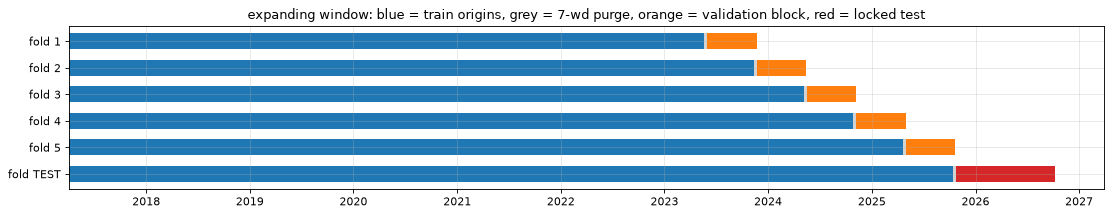

In [48]:
fig, ax = plt.subplots(figsize=(14, 2.8))
for k, r_ in ft.iterrows():
    y = len(ft) - k
    seg = lambda a, b, c: ax.barh(y, (pd.Timestamp(b) - pd.Timestamp(a)).days, left=pd.Timestamp(a), color=c, height=.6)
    seg(r_.train_from, r_.train_last_origin, "tab:blue"); seg(r_.train_last_origin, r_.val_from, "lightgrey")
    seg(r_.val_from, r_.val_to, "tab:red" if r_.fold == "TEST" else "tab:orange")
ax.set_yticks(range(1, len(ft) + 1)); ax.set_yticklabels([f"fold {f}" for f in ft.fold][::-1])
ax.set_title("expanding window: blue = train origins, grey = 7-wd purge, orange = validation block, red = locked test"); plt.show()

The printed boundaries confirm the purge: in every fold the **last training label date is strictly before the first validation origin**. Training sets grow from about 8,800 to 11,800 rows, and each validation block has about 750 (province, origin) rows.
The test year has 1,500 rows, and its training set ends 7 working days before it starts.

## 8. Metrics and baseline models

**Primary metric : MAPE, macro-averaged over provinces** (compute MAPE per province, then take the plain mean). MAE and RMSE in Rp/kg are reported alongside.
* The brief says "MAPE only when valid". It is valid here: prices are strictly positive and never near zero (minimum about Rp 10,000/kg), so the percentage error is well defined and stable.
* Price levels differ across provinces (Jakarta averages about Rp 60k vs about Rp 41k in Jawa Timur), and the stakeholder thinks in relative terms ("+30% next week"). Macro-averaged MAPE weights every province equally. RMSE would let the most expensive provinces and spike periods dominate model selection.
* Known weakness: MAPE penalises over-forecasts more than under-forecasts of the same size, which mildly favours low forecasts. MAE and RMSE are shown next to it so this stays visible.

In [49]:
def metrics(frame, pred_col):
    # per-province MAPE / MAE / RMSE, then the macro average (each province counts equally)
    out = {}
    for p, g_ in frame.groupby("province"):
        e = g_[pred_col] - g_["target_price"]
        out[p] = {"MAPE": 100 * np.mean(np.abs(e) / g_["target_price"]), "MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2))}
    m = pd.DataFrame(out).T
    return m, {"MAPE": m.MAPE.mean(), "MAE": m.MAE.mean(), "RMSE": m.RMSE.mean()}

def fold_table(pred, folds=FOLDS):
    # score a prediction Series (indexed like `data`) on every CV fold
    rows = []
    for k, (tr, va) in enumerate(folds):
        _, agg = metrics(data.loc[va, ["province", "target_price"]].assign(p=pred.loc[va]).dropna(), "p"); agg["fold"] = k + 1; rows.append(agg)
    return pd.DataFrame(rows).set_index("fold")

**Baselines:**
* **Naive (persistence):** ŷ(t+7) = last known price at t. For a highly persistent series (Section 5.3) this is the benchmark that matters.
* **Seasonal-naive (annual):** ŷ(t+7) = the price at the same working day one year earlier (t + 7 − 260). The README named a seasonal-naive benchmark. We evaluate it, though Section 5.2 suggests it will be weak.
  A *weekly* seasonal-naive is not meaningful here: there is no day-of-week pattern, and with m = 5 < h = 7 it would just be a staler persistence forecast.

In [50]:
PRED = {}                                                            # every model's CV predictions, indexed like `data`
PRED["naive"]  = data["price_ff"]                                    # last known price
PRED["snaive"] = data.groupby("province")["price_ff"].shift(260 - H) # same working day last year
cv_res = {m: fold_table(PRED[m]) for m in ["naive", "snaive"]}
pd.DataFrame({m: v.MAPE for m, v in cv_res.items()}).T.assign(mean=lambda x: x.mean(axis=1)).round(2)

fold,1,2,3,4,5,mean
naive,14.06,17.77,14.93,21.20,14.88,16.57
snaive,83.65,31.75,35.89,64.12,30.19,49.12


**Persistence is far stronger than the annual seasonal-naive** (≈ 16.6% vs ≈ 49% MAPE). Last year's price at the same date is a poor guess for next week because the cycles do not repeat in level or timing.
**The naive forecast is the bar every candidate must clear.** On a near-random-walk commodity price at a 7-day horizon, beating persistence by even a few percentage points of MAPE is meaningful.

## 9. Candidate models

The brief asks for at least 3 forecasting approaches. We use **five, from different families**, all evaluated on the **same folds, same rows, same metric**:

| Model | Family | Inputs | Why it is in the line-up |
|---|---|---|---|
| **ETS** (Holt, additive damped trend) on log price | exponential smoothing, per province | own series | classical benchmark for a persistent series with a drifting level. Damping stops 7-step trend extrapolation from running away |
| **ARIMA(1,1,1)** on log price | Box-Jenkins state space, per province | own series (the Kalman filter handles NaN) | short AR/MA structure from the PACF (Section 5.3). The order and `d` are tuned later if selected |
| **Ridge** regression | linear, global | engineered features. Imputation and scaling are fitted **inside a pipeline on each training fold only** | tests whether a linear combination of the features is enough. Regularisation handles the many correlated lag features |
| **Random Forest** | bagged trees, global | engineered features | non-linear and robust to outliers and irrelevant features |
| **LightGBM** | gradient-boosted trees, global | engineered features (native NaN handling) | usually the strongest learner on tabular lag features, and fast enough to tune |

ETS and ARIMA forecast the log **level** 7 steps ahead. Ridge, RF and LightGBM predict the 7-day **log change** (Section 3.5). All forecasts are converted to Rp/kg before scoring.

### 9.1 Classical models: ETS and ARIMA with rolling origins

Parameters are estimated on the training window only, then **filtered forward through the validation block with fixed parameters**, so that each origin t gets a genuine 7-step forecast from data ≤ t (no refit, no future data).
The 7-step forecast is computed in closed form from the filtered state, which is much faster than about 750 separate `forecast()` calls per fold. It is **asserted equal to statsmodels' own `forecast()`** at the end of the training window.

In [51]:
def ets_rolling(y, n_train, damped=True, trend="add"):
    # Holt's additive (damped) trend; statsmodels parameterisation (beta is the 'smoothing_trend' = beta*)
    fit = ExponentialSmoothing(y[:n_train], trend=trend, damped_trend=bool(trend) and damped, initialization_method="estimated").fit()
    a = fit.params["smoothing_level"]
    b = (fit.params.get("smoothing_trend") or 0.0) if trend else 0.0
    phi = fit.params.get("damping_trend", 1.0) if (trend and damped) else 1.0
    l, bb = fit.params["initial_level"], ((fit.params.get("initial_trend") or 0.0) if trend else 0.0)
    mult = sum(phi ** i for i in range(1, H + 1))                    # h-step damped-trend multiplier
    fc = np.empty(len(y))
    for t in range(len(y)):                                          # filter forward with FIXED parameters
        l_new = a * y[t] + (1 - a) * (l + phi * bb)
        bb = b * (l_new - l) + (1 - b) * phi * bb if trend else 0.0
        l = l_new; fc[t] = l + mult * bb                             # forecast for t+H made at t
    assert np.isclose(fc[n_train - 1], fit.forecast(H)[-1], atol=1e-6), "ETS recursion != statsmodels"
    return fc

**ARIMA, same principle.** `res.apply(y)` re-runs the Kalman filter over the full series with the *training* parameters. The filtered state $a(t|t)$ uses data up to $t$ only, and the 7-step forecast is $Z\left(T^{7}\,a(t|t) + \displaystyle\sum_{j=0}^{6} T^{j}c\right)$. Missing days are handled natively by the filter, so the raw (unfilled) price is used.

In [52]:
def arima_rolling(y, n_train, order=(1, 1, 1)):
    trend = "c" if order[1] == 0 else "n"                            # a stationary model needs a mean; a differenced one doesn't
    res = SARIMAX(y[:n_train], order=order, trend=trend).fit(disp=False, maxiter=200)
    fr = res.apply(y).filter_results                                 # same parameters, Kalman filter over ALL data (NaN-aware)
    assert fr.transition.shape[-1] == 1 and fr.design.shape[-1] == 1, "time-invariant system expected"
    T, Z = fr.transition[:, :, 0], fr.design[:, :, 0]
    c = fr.state_intercept[:, 0]; assert np.allclose(fr.state_intercept, c[:, None])
    d0 = fr.obs_intercept[:, 0]
    TH = np.linalg.matrix_power(T, H); cH = sum(np.linalg.matrix_power(T, j) @ c for j in range(H))
    fc = (Z @ (TH @ fr.filtered_state + cH[:, None]) + d0[:, None]).ravel()    # E[y_{t+H} | y_{1..t}] for every t
    assert np.isclose(fc[n_train - 1], res.forecast(H)[-1], atol=1e-6), "closed-form ARIMA forecast != statsmodels"
    return fc

A wrapper applies either model per province for one split, and `cv_ts` loops over the five folds. ETS needs a gap-free series, so it uses the forward-filled price. ARIMA uses the raw price with NaN.

In [53]:
def ts_model_predict(kind, split_start, **kw):
    # fit on observations dated < split_start (everything known at the first origin), forecast every origin of every province
    preds = pd.Series(np.nan, index=data.index)
    for p in PROVINCES:
        ix = data.index[data.province == p]
        n_tr = int(np.searchsorted(data.loc[ix, "date"].values, np.datetime64(split_start)))
        if kind == "ets":
            fc = ets_rolling(np.log(data.loc[ix, "price_ff"]).values, n_tr, **kw)   # ETS needs a gap-free series -> ffilled
        else:
            fc = arima_rolling(np.log(data.loc[ix, "price"]).values, n_tr, **kw)    # raw with NaN: the Kalman filter skips gaps
        preds.loc[ix] = np.exp(fc)
    return preds

def cv_ts(kind, **kw):
    pred = pd.Series(np.nan, index=data.index)
    for tr, va in FOLDS:
        pred.loc[va] = ts_model_predict(kind, data.loc[va, "date"].min(), **kw).loc[va]
    return pred

t_ = time.time()
for kind in ["ets", "arima"]:
    PRED[kind] = cv_ts(kind); cv_res[kind] = fold_table(PRED[kind])
print(f"ETS + ARIMA rolling-origin CV in {time.time() - t_:.0f}s; closed-form forecasts verified against statsmodels in every fit")

ETS + ARIMA rolling-origin CV in 18s; closed-form forecasts verified against statsmodels in every fit


*Same information set as the ML models.* ETS/ARIMA are fitted on observations up to the day before the validation block. For a univariate model the "labels" are just the series itself, so this is exactly what is known at the first validation origin. The ML purge rule (`target_date < block start`) gives them the same information.

### 9.2 Global ML models: Ridge, Random Forest, LightGBM

All three are trained on the 7-day log change and share one helper, so preprocessing, rows and scoring are identical.
Defaults are deliberately plain: library defaults for LightGBM and Ridge, and a common RF configuration (300 trees, `min_samples_leaf=5`, `max_features=0.33`) because sklearn's RF defaults (fully grown trees on all features) are slow and overfit on 80 noisy features.

In [54]:
FEATURES_ALL = [c for g_ in GROUPS.values() for c in g_]

def make_model(kind, params=None):
    params = dict(params or {}); params.pop("train_years", None)
    if kind == "lgbm":
        return lgb.LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=8, **params)
    if kind == "rf":
        base = dict(n_estimators=300, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=SEED); base.update(params)
        # imputer inside the pipeline -> medians come from the training fold only
        return make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(**base))
    if kind == "ridge":
        # scaler inside the pipeline -> means/SDs from the training fold only (brief Section 10: fit preprocessing on train only)
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=params.get("alpha", 1.0)))
    raise ValueError(kind)

def fit_predict(kind, feats, tr, va, params=None):
    params = params or {}
    if params.get("train_years"):                                    # optional rolling (not expanding) training window
        tr = tr[data.loc[tr, "date"] >= data.loc[va, "date"].min() - pd.DateOffset(years=int(params["train_years"]))]
    m = make_model(kind, params).fit(data.loc[tr, feats], data.loc[tr, "y_logret"])
    return data.loc[va, "price_ff"] * np.exp(m.predict(data.loc[va, feats])), m   # back-transform: P[t] * exp(predicted log change)

def cv_ml(kind, feats, params=None):
    pred = pd.Series(np.nan, index=data.index)
    for tr, va in FOLDS:
        pred.loc[va] = fit_predict(kind, feats, tr, va, params)[0]
    return pred

Run the three ML candidates on the five folds with all engineered features, then build the comparison table for all models so far. `summarise` also counts in how many folds each model beats naive, which is more robust than the mean alone.

In [55]:
# Same folds, same rows, same metric as the baselines and ETS/ARIMA -> directly comparable numbers
t_ = time.time()
for kind in ["ridge", "rf", "lgbm"]:
    PRED[kind] = cv_ml(kind, FEATURES_ALL); cv_res[kind] = fold_table(PRED[kind])
print(f"ML CV (all {len(FEATURES_ALL)} features) in {time.time() - t_:.0f}s")

def summarise(res):
    s = pd.DataFrame({k: {"CV MAPE": v.MAPE.mean(), "MAPE sd over folds": v.MAPE.std(), "MAE": v.MAE.mean(), "RMSE": v.RMSE.mean(),
                          "folds beating naive": int((v.MAPE < res["naive"].MAPE).sum())} for k, v in res.items()}).T
    s["skill vs naive %"] = 100 * (1 - s["CV MAPE"] / s.loc["naive", "CV MAPE"])
    return s.sort_values("CV MAPE").round(2)
summarise(cv_res)

ML CV (all 79 features) in 35s


,CV MAPE,MAPE sd over folds,MAE,RMSE,folds beating naive,skill vs naive %
ridge,15.17,3.18,7802.60,10312.95,4.0,8.43
rf,15.28,3.28,7994.76,10557.12,4.0,7.77
lgbm,15.42,3.42,8068.17,10541.90,4.0,6.96
ets,15.81,3.05,8037.26,10857.05,5.0,4.59
arima,15.82,3.03,8040.26,10865.06,5.0,4.54
naive,16.57,2.95,8296.20,11094.13,0.0,0.00
snaive,49.12,23.73,22674.24,27950.67,0.0,-196.47


Fold-by-fold view of the same numbers. If fold difficulty varies a lot, model differences must be judged fold by fold (paired), not from the overall average.

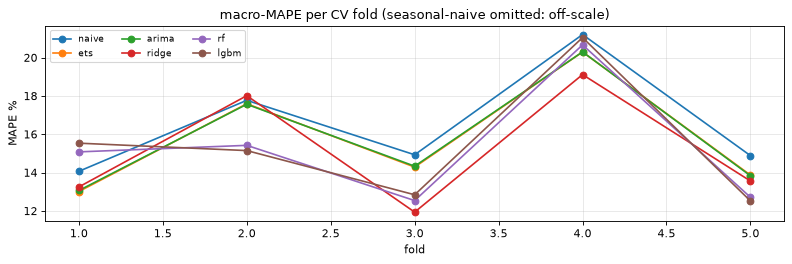

In [56]:
fig, ax = plt.subplots(figsize=(10, 3.4))
pd.DataFrame({k: v.MAPE for k, v in cv_res.items() if k != "snaive"}).plot(marker="o", ax=ax)
ax.set(title="macro-MAPE per CV fold (seasonal-naive omitted: off-scale)", xlabel="fold", ylabel="MAPE %"); ax.legend(fontsize=8, ncol=3); plt.show()

**First comparison (all 79 features, default settings):**
* **Every candidate beats persistence on average.** The three global feature-based models reach CV MAPE ≈ 15.2-15.4% (skill ≈ 7-8% vs naive), with Ridge ahead (15.17%) of Random Forest (15.28%) and LightGBM (15.42%). The single-series ETS and ARIMA reach ≈ 15.8% (skill ≈ 4.6%).
  This is a hard series, as Section 3.5 predicted, and the gap between "features" and "own history only" is the first sign that the engineered inputs carry real information.
* ETS and ARIMA beat naive in **all 5 folds**, but only by a small margin: they essentially add a damped drift to persistence. The ML models win on average but beat naive in only 4 of 5 folds at this stage: in fold 1 (Jun-Nov 2023) RF and LightGBM are clearly *worse* than naive, and Ridge is slightly worse than naive in fold 2 (Nov 2023 - May 2024).
* The fold plot shows that **fold difficulty dominates model differences**: all models move together from the easier blocks (≈ 12-15%) to the hardest one (fold 4, Nov 2024 - Apr 2025, ≈ 19-21%). Model rankings must be judged on paired, fold-by-fold differences.
* With 79 features the three ML families are within 0.3 pp of each other, and the tree models are the least stable across folds. One suspicion is that some groups add noise, tested directly next.

### 9.2b Sanity check: how much would shuffled K-fold have flattered us?

The same default LightGBM and the same features, scored with **shuffled 5-fold K-fold** on the development period instead of chronological folds.

In [57]:
dev_idx = data.index[(data.target_date < TEST_START) & has_y]
kf = []
for tr_i, va_i in KFold(5, shuffle=True, random_state=SEED).split(dev_idx):
    p_, _ = fit_predict("lgbm", FEATURES_ALL, dev_idx[tr_i], dev_idx[va_i])
    kf.append(metrics(data.loc[dev_idx[va_i], ["province", "target_price"]].assign(p=p_), "p")[1]["MAPE"])
print(f"LightGBM macro-MAPE: shuffled K-fold {np.mean(kf):.2f}%  vs  chronological expanding-window CV {cv_res['lgbm'].MAPE.mean():.2f}%")

LightGBM macro-MAPE: shuffled K-fold 7.22%  vs  chronological expanding-window CV 15.42%


Shuffled K-fold reports **less than half** the honest error. That gap is **pure leakage**: the model "predicts" a day by interpolating between near-identical neighbours whose labels it has seen.
This is why the brief treats inappropriate time-series splitting as a major methodological error, and why every decision in this notebook uses the chronological folds.

### 9.3 Feature-group ablation: which engineered groups actually help? (three model families)

Feature choices should not depend on one model's quirks, so each group is tested by **dropping it from the full set** and re-running the CV for **Ridge, Random Forest and LightGBM** (default settings).
Drop-one-group is order-independent, unlike adding groups cumulatively. For the calendar we also test a **lean** variant (windows + smooth seasonality only), as motivated in Section 6.5.

**Keep rule :** keep a group if removing it makes CV MAPE **worse on average across the three families and worse for at least 2 of the 3**. `own` and `prov` are always kept, since they are the core of the forecast.

In [58]:
def without(*gs): return [c for c in FEATURES_ALL if not any(c in GROUPS[g_] for g_ in gs)]
ABL = {"all": FEATURES_ALL, **{f"- {g_}": without(g_) for g_ in ["xprov", "cal", "wx_base", "wx_ext", "wx_extra", "solar"]},
       "cal -> lean": without("cal") + CAL_LEAN}
t_ = time.time()
abl = {(name, kind): fold_table(cv_ml(kind, feats)) for name, feats in ABL.items() for kind in ["ridge", "rf", "lgbm"]}
print(f"ablation: {len(abl)} CV runs in {time.time() - t_:.0f}s")
abl_tab = pd.DataFrame({name: {kind: abl[(name, kind)].MAPE.mean() for kind in ["ridge", "rf", "lgbm"]} for name in ABL}).T
abl_tab["mean of 3"] = abl_tab.mean(axis=1); abl_tab.round(3)

ablation: 24 CV runs in 255s


,ridge,rf,lgbm,mean of 3
all,15.173,15.281,15.416,15.290
- xprov,15.323,16.049,16.704,16.025
- cal,14.476,14.879,15.293,14.883
- wx_base,15.279,15.370,15.316,15.321
- wx_ext,15.338,15.400,15.808,15.516
- wx_extra,15.060,15.360,15.099,15.173
- solar,14.926,15.368,15.081,15.125
cal -> lean,15.065,15.273,15.326,15.221


The same results as **paired differences** (without the group minus with all groups, per family), which removes the shared fold difficulty and isolates each group's contribution.

In [59]:
# Paired view: change in MAPE when the group is REMOVED (positive = the group was helping)
eff = pd.DataFrame({name: {kind: (abl[(name, kind)].MAPE - abl[("all", kind)].MAPE).mean() for kind in ["ridge", "rf", "lgbm"]}
                    for name in ABL if name != "all"}).T
eff["mean"] = eff.mean(axis=1); eff["families hurt by removal"] = (eff[["ridge", "rf", "lgbm"]] > 0).sum(axis=1)
eff.round(3)

,ridge,rf,lgbm,mean,families hurt by removal
- xprov,0.150,0.768,1.288,0.735,3
- cal,-0.697,-0.402,-0.122,-0.407,0
- wx_base,0.106,0.089,-0.100,0.032,2
- wx_ext,0.166,0.119,0.392,0.226,3
- wx_extra,-0.113,0.079,-0.316,-0.117,1
- solar,-0.247,0.087,-0.335,-0.165,1
cal -> lean,-0.107,-0.008,-0.090,-0.068,0


How to read the paired table: each cell is *MAPE without the group and MAPE with all groups*. **Positive means the group helps**, because removing it hurts. For "cal → lean", positive means the full calendar set beats the lean one.

In [60]:
# Solar encoding equivalence, demonstrated: raw Rp/L vs regime flag -> identical LightGBM predictions
tr, va = FOLDS[-1]
pa, _ = fit_predict("lgbm", OWN + PROV + ["solar_rp_per_l"], tr, va)
pb, _ = fit_predict("lgbm", OWN + PROV + ["solar_post_sep2022"], tr, va)
print("max |prediction difference|, raw Rp/L vs flag:", float(np.abs(pa - pb).max()), "Rp/kg")

max |prediction difference|, raw Rp/L vs flag: 0.0 Rp/kg


The two Solar encodings give **identical** predictions, which confirms Section 6.6: a second Solar column would add nothing.

Now the keep rule is applied mechanically to the ablation results:

In [61]:
KEEP = {"own": True, "prov": True}
for g_ in ["xprov", "cal", "wx_base", "wx_ext", "wx_extra", "solar"]:
    e = eff.loc[f"- {g_}"]
    KEEP[g_] = bool(e["mean"] > 0 and e["families hurt by removal"] >= 2)
# calendar: if the full set is not kept, is the lean variant better than no calendar at all?
cal_choice = "full" if KEEP["cal"] else None
if not KEEP["cal"]:
    lean_vs_none = (abl_tab.loc["cal -> lean", ["ridge", "rf", "lgbm"]] - abl_tab.loc["- cal", ["ridge", "rf", "lgbm"]])
    cal_choice = "lean" if (lean_vs_none.mean() < 0 and (lean_vs_none < 0).sum() >= 2) else "none"
FEATURES_FINAL = [c for g_ in GROUPS for c in GROUPS[g_] if KEEP[g_]] + (CAL_LEAN if cal_choice == "lean" else [])
print("keep decisions:", KEEP, "| calendar:", cal_choice)
print(f"FEATURES_FINAL: {len(FEATURES_FINAL)} features")

keep decisions: {'own': True, 'prov': True, 'xprov': True, 'cal': False, 'wx_base': True, 'wx_ext': True, 'wx_extra': False, 'solar': False} | calendar: none
FEATURES_FINAL: 59 features


**What the ablation says:**
* **Cross-province features are the most valuable engineered group.** Removing them hurts all three families (+0.15 pp Ridge, +0.77 pp RF, +1.29 pp LightGBM). This confirms the Section 5.6 finding with real out-of-sample evidence: other provinces' recent moves, Jawa Timur's especially, improve 7-day forecasts beyond the province's own history. The tree models exploit this most.
* **The data-driven lagged rain windows (`wx_ext`) help**: all three families get worse without them (mean +0.23 pp, LightGBM +0.39 pp). The Section 5.7 scan found real, usable signal that `fetch_weather.py`'s fixed windows did not provide.
  Caveat: these windows were chosen on the same development period the CV evaluates, so part of this gain may be selection optimism. The locked test year is the independent check.
* The base weather (`wx_base`) is **essentially neutral** (mean +0.03 pp): it helps Ridge (+0.11 pp) and RF (+0.09 pp) but hurts LightGBM (−0.10 pp). It passes the keep rule (2 of 3 families) only narrowly.
* **Radiation/ET0 (`wx_extra`, the four panel columns) is dropped.** Removing it *improves* Ridge (−0.11 pp) and LightGBM (−0.32 pp), and only RF benefits from it (+0.08 pp), so the mean is −0.12 pp with 1 of 3 families. Radiation and ET0 windows correlate with price about as strongly as rain's (Section 5.8), but that information is redundant with the rain windows once those are in the model.
* **Calendar: the most important negative result.** The holiday features, the top prior hypothesis, **make all three families worse** (removing them improves MAPE by 0.70 pp for Ridge, 0.40 pp for RF, 0.12 pp for LightGBM). The lean variant (windows + smooth seasonality only) is also worse than no calendar at all in every family. So the calendar group is **dropped**.
  This is consistent with the event study (Section 5.9: no stable pre-Lebaran surge in this sample). The likely mechanism of harm is that continuous "days to X" counts let models fit year-specific episodes that do not recur.
  It does **not** show that holidays don't matter for prices. It shows that, given recent prices in all six provinces, the calendar adds no *extra* 7-day predictive information here.
* **Solar is dropped** by the rule (mean −0.17 pp; only RF is slightly hurt by its removal, +0.09 pp, while Ridge improves by 0.25 pp and LightGBM by 0.34 pp without it), as anticipated in Section 6.6: one step change in 2022 cannot help predict 2023-2025 blocks in which it is constant. Which single family it "helps" changes with the rest of the feature set, another sign that its effect is noise.

Dropped groups stay built and documented, so the group can overrule the mechanical rule on domain grounds.

In [62]:
for kind in ["ridge", "rf", "lgbm"]:
    PRED[kind] = cv_ml(kind, FEATURES_FINAL); cv_res[kind] = fold_table(PRED[kind])
cand_summary = summarise(cv_res); cand_summary

,CV MAPE,MAPE sd over folds,MAE,RMSE,folds beating naive,skill vs naive %
ridge,14.04,2.52,7338.01,9891.44,5.0,15.25
lgbm,14.75,3.56,7721.07,10092.42,5.0,10.99
rf,14.93,3.33,7777.04,10157.88,5.0,9.88
ets,15.81,3.05,8037.26,10857.05,5.0,4.59
arima,15.82,3.03,8040.26,10865.06,5.0,4.54
naive,16.57,2.95,8296.20,11094.13,0.0,0.00
snaive,49.12,23.73,22674.24,27950.67,0.0,-196.47


This table is the **default-model comparison** on the final 59-feature set (own, province, cross-province, base weather and lagged rain windows). Removing the calendar, radiation/ET0 and Solar groups **improved every ML model**: Ridge 15.17 → 14.04%, RF 15.28 → 14.93%, LightGBM 15.42 → 14.75%. 

All three now beat naive in all 5 folds.
**Ridge (14.04%, skill 15% vs naive) and LightGBM (14.75%)** are the two strongest non-baseline models and are carried into tuning; Random Forest (14.93%) drops out.
A linear model winning is informative in itself: with a noisy target and about 12k training rows, a well-regularised linear combination of good features generalises better than flexible trees.

## 10. Hyperparameter tuning

**Which models:** the **two strongest non-baseline models** from Section 9.4, selected mechanically (the code adapts to whichever two come out on top).

**Method:** randomised search (`ParameterSampler`) for the tree models, and an exhaustive grid for small spaces (Ridge, ETS, ARIMA). Every configuration is scored on **the same 5 expanding-window folds with the same metric (macro-MAPE in Rp/kg)** used for model selection, so the tuning metric and the selection metric are identical.
We use our own loop instead of `RandomizedSearchCV` because the folds are date-based with a purge across a 6-province panel, and the scorer needs the back-transform from log change to price. The test year is never touched.

**Search spaces and why:**
* **LightGBM:** `num_leaves` and `min_child_samples` (tree complexity vs leaf size: is the default too complex for noisy targets?); `learning_rate` with `n_estimators` (the boosting budget); `colsample_bytree`/`subsample` (decorrelation over about 60 correlated lag features); `reg_lambda`; and `objective` ∈ {L2, L1, Huber}, because the targets are heavy-tailed (Section 3.5) and L1/Huber are closer to an absolute-percentage loss.
* **Random Forest:** `max_features` (decorrelation), `min_samples_leaf` and `max_depth` (smoothing of noisy targets), and `n_estimators`.
* **Ridge:** `alpha` over 6 orders of magnitude, plus `train_years` ∈ {all, 6, 4, 2}. That is the **training-window length**: does dropping old regimes (pre-2022 reporting practice, older price levels) help? Both are real hyperparameters of a time-series regression.
* **ARIMA:** `(p, d, q)` with p, q ∈ {0, 1, 2} and d ∈ {0, 1}. `d = 0` is included because the ADF test rejected a unit root (Section 5.3).
* **ETS:** trend ∈ {additive, none} × damping ∈ {on, off}.

The **feature set is held fixed** at `FEATURES_FINAL` for both default and tuned versions, so the comparison isolates the effect of the hyperparameters.

In [63]:
SPACES = {
    "lgbm":  {"n_estimators": [100, 200, 400, 700], "learning_rate": [0.01, 0.02, 0.05, 0.1], "num_leaves": [7, 15, 31, 63],
              "min_child_samples": [20, 50, 100, 200], "colsample_bytree": [0.3, 0.5, 0.8, 1.0], "subsample": [0.6, 0.8, 1.0],
              "subsample_freq": [1], "reg_lambda": [0, 1, 10], "objective": ["regression", "regression_l1", "huber"]},
    "rf":    {"n_estimators": [200, 400], "max_features": [0.1, 0.2, 0.33, 0.5], "min_samples_leaf": [1, 5, 20, 50], "max_depth": [None, 8, 16]},
    "ridge": {"alpha": [0.1, 1, 10, 100, 1e3, 3e3, 1e4, 3e4, 1e5], "train_years": [None, 6, 4, 2]},
    "arima": {"order": [(p, d, q) for d in (1, 0) for p in (0, 1, 2) for q in (0, 1, 2)]},
    "ets":   {"trend": ["add", None], "damped": [True, False]},
}
N_ITER = {"lgbm": 40, "rf": 12}                 # random-search budgets: RF is ~10x slower per fit than LightGBM
TOP2 = [m for m in cand_summary.index if m not in ("naive", "snaive")][:2]
print("models selected for tuning (by default CV macro-MAPE):", TOP2)

models selected for tuning (by default CV macro-MAPE): ['ridge', 'lgbm']


The search loop: random sampling for the large tree spaces, a full grid for the small ones, and every configuration scored by the identical CV routine used for model selection.

In [64]:
def candidate_grid(kind):
    if kind in N_ITER:
        return list(ParameterSampler(SPACES[kind], n_iter=N_ITER[kind], random_state=SEED))
    keys = list(SPACES[kind]); vals = [SPACES[kind][k] for k in keys]
    combos = [dict(zip(keys, v)) for v in __import__("itertools").product(*vals)]
    return [c for c in combos if not (kind == "ets" and c["trend"] is None and c["damped"])]   # damping needs a trend

def cv_config(kind, prm):
    return fold_table(cv_ml(kind, FEATURES_FINAL, prm) if kind in ("lgbm", "rf", "ridge") else cv_ts(kind, **prm))

tuning, BEST = {}, {}
for kind in TOP2:
    t_ = time.time(); rows = []
    for prm in candidate_grid(kind):
        s = cv_config(kind, prm); rows.append({**{k: str(v) if isinstance(v, tuple) else v for k, v in prm.items()},
                                               "CV MAPE": s.MAPE.mean(), "sd": s.MAPE.std(), "_prm": prm})
    tuning[kind] = pd.DataFrame(rows).sort_values("CV MAPE").reset_index(drop=True)
    BEST[kind] = tuning[kind].loc[0, "_prm"]
    print(f"{kind}: {len(rows)} configurations in {time.time() - t_:.0f}s | best: {BEST[kind]}")

ridge: 36 configurations in 12s | best: {'alpha': 100, 'train_years': 6}


lgbm: 40 configurations in 153s | best: {'subsample_freq': 1, 'subsample': 1.0, 'reg_lambda': 0, 'objective': 'regression', 'num_leaves': 7, 'n_estimators': 700, 'min_child_samples': 100, 'learning_rate': 0.02, 'colsample_bytree': 1.0}


Top configurations per tuned model. If several configurations are close to the best, the search surface is flat, which is a sign that tuning will matter little.

In [65]:
for kind in TOP2:
    print(f"\n=== {kind}: top configurations (CV macro-MAPE, lower is better) ===")
    display(tuning[kind].drop(columns="_prm").head(8).round(3))


=== ridge: top configurations (CV macro-MAPE, lower is better) ===


,alpha,train_years,CV MAPE,sd
0,100.0,6.0,13.894,2.452
1,10.0,6.0,13.993,2.229
2,10.0,NaN,14.039,2.530
3,1.0,NaN,14.042,2.522
4,0.1,NaN,14.042,2.521
5,100.0,NaN,14.044,2.570
6,1.0,6.0,14.068,2.174
7,0.1,6.0,14.080,2.167



=== lgbm: top configurations (CV macro-MAPE, lower is better) ===


,subsample_freq,subsample,reg_lambda,objective,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree,CV MAPE,sd
0,1,1.0,0,regression,7,700,100,0.02,1.0,14.300,3.184
1,1,1.0,1,huber,7,200,100,0.05,0.5,14.321,3.205
2,1,1.0,0,huber,15,200,100,0.02,0.3,14.379,3.029
3,1,0.8,1,regression_l1,7,700,50,0.01,0.3,14.396,2.944
4,1,0.6,0,regression_l1,31,100,200,0.05,1.0,14.418,3.196
5,1,0.8,10,huber,15,100,100,0.05,0.5,14.438,3.284
6,1,0.6,0,regression,15,400,20,0.02,0.8,14.479,3.353
7,1,1.0,0,regression,7,200,20,0.10,0.8,14.488,3.135


Default vs tuned on identical folds and features, with fold counts. This is the brief's required default-versus-tuned comparison.

In [66]:
dvt = []
for kind in TOP2:
    cv_res[f"{kind}_tuned"] = cv_config(kind, BEST[kind])
    d_, t2 = cv_res[kind], cv_res[f"{kind}_tuned"]
    dvt.append({"model": kind, "best params": BEST[kind], "default CV MAPE": d_.MAPE.mean(), "tuned CV MAPE": t2.MAPE.mean(),
                "default MAE": d_.MAE.mean(), "tuned MAE": t2.MAE.mean(), "folds improved": f"{int((t2.MAPE < d_.MAPE).sum())}/5"})
DVT = pd.DataFrame(dvt).set_index("model"); DVT["gain (MAPE pp)"] = DVT["default CV MAPE"] - DVT["tuned CV MAPE"]
DVT.round(3)

,best params,default CV MAPE,tuned CV MAPE,default MAE,tuned MAE,folds improved,gain (MAPE pp)
model,,,,,,,
ridge,"{'alpha': 100, 'train_years': 6}",14.042,13.894,7338.010,7346.918,3/5,0.148
lgbm,"{'subsample_freq': 1, 'subsample': 1.0, 'reg_l...",14.748,14.300,7721.069,7420.881,4/5,0.448


**Reading the tuning results:**
* **Ridge:** best `alpha = 100` with `train_years = 6`: CV MAPE 14.04 → **13.89%** (−0.15 pp), better in 3 of 5 folds, while CV MAE is essentially unchanged (7,338 → 7,347 Rp). Dropping the oldest years (2017-2019, when PIHPS still left holidays blank and price levels were lower) helps a little in MAPE terms.
  The top eight configurations sit within ≈ 0.2 pp of each other, so the search surface is **flat** and the exact alpha matters little.
* **LightGBM:** best `num_leaves = 7`, `min_child_samples = 100`, `learning_rate = 0.02` with 700 trees, L2 objective, no row/column subsampling: 14.75 → **14.30%** (−0.45 pp), better in **4 of 5 folds**, and MAE improves too (7,721 → 7,421 Rp). As expected for a noisy target, **small trees with large leaves and a slow learning rate** win over the default (31 leaves, 20-row leaves).
  The runners-up use Huber or L1 objectives within ≈ 0.1 pp, so the loss function matters less than tree size.
* LightGBM gains more from tuning than Ridge and gets the lowest CV RMSE of all models, but tuned Ridge still has the **lowest CV MAPE** (13.89% vs 14.30%). Both gains are modest relative to fold-to-fold spread (SD ≈ 2.5-3.2 pp). Most of the gain over persistence came from **feature engineering and feature selection** (Section 9.3-9.4), not from hyperparameters.

## 11. Model evaluation on the locked test year

**Selection rule, fixed before looking at test:** the final model is the configuration (default or tuned) with the **lowest mean CV macro-MAPE**.
All candidates are then refitted on all development data (purge: `target_date < TEST_START`) and scored **once** on the test year. ETS/ARIMA are filtered forward with fixed parameters as in CV. Test numbers are **reported, not used to choose**.

In [67]:
all_cv = summarise(cv_res)
FINAL = [m for m in all_cv.index if m not in ("naive", "snaive")][0]
print("FINAL model (lowest CV MAPE):", FINAL)
all_cv

FINAL model (lowest CV MAPE): ridge_tuned


,CV MAPE,MAPE sd over folds,MAE,RMSE,folds beating naive,skill vs naive %
ridge_tuned,13.89,2.45,7346.92,9960.50,5.0,16.14
ridge,14.04,2.52,7338.01,9891.44,5.0,15.25
lgbm_tuned,14.30,3.18,7420.88,9746.78,5.0,13.69
lgbm,14.75,3.56,7721.07,10092.42,5.0,10.99
rf,14.93,3.33,7777.04,10157.88,5.0,9.88
ets,15.81,3.05,8037.26,10857.05,5.0,4.59
arima,15.82,3.03,8040.26,10865.06,5.0,4.54
naive,16.57,2.95,8296.20,11094.13,0.0,0.00
snaive,49.12,23.73,22674.24,27950.67,0.0,-196.47


Refit every candidate on all development data (purged) and score it once on the locked test year. ETS/ARIMA are refitted on data up to the day before the test year and then filtered forward, exactly as in CV.

In [68]:
MODELS = {}          # fitted ML models on the full development set, kept for interpretation
def test_predict(name):
    if name == "naive":  return PRED["naive"].loc[TEST_VA]
    if name == "snaive": return PRED["snaive"].loc[TEST_VA]
    kind, tuned = name.replace("_tuned", ""), name.endswith("_tuned")
    prm = BEST[kind] if tuned else {}
    if kind in ("ets", "arima"):
        return ts_model_predict(kind, TEST_START, **prm).loc[TEST_VA]
    p_, m_ = fit_predict(kind, FEATURES_FINAL, TEST_TR, TEST_VA, prm)
    MODELS[name] = m_
    return p_

TEST = data.loc[TEST_VA, ["date", "province", "price_ff", "target_price", "target_date"]].copy()
for name in all_cv.index:
    TEST[f"p_{name}"] = test_predict(name)
test_tab = pd.DataFrame({name: {**{f"test {k}": v for k, v in metrics(TEST, f"p_{name}")[1].items()}, "CV MAPE": all_cv.loc[name, "CV MAPE"]}
                         for name in all_cv.index}).T
test_tab["test skill vs naive %"] = 100 * (1 - test_tab["test MAPE"] / test_tab.loc["naive", "test MAPE"])
test_tab.sort_values("CV MAPE").round(2)

,test MAPE,test MAE,test RMSE,CV MAPE,test skill vs naive %
ridge_tuned,14.11,9316.17,11772.87,13.89,7.16
ridge,13.68,9061.48,11626.60,14.04,9.99
lgbm_tuned,13.00,8615.97,11358.81,14.30,14.49
lgbm,13.43,8900.08,11681.32,14.75,11.61
rf,13.55,9036.07,11900.60,14.93,10.88
ets,14.78,9506.61,12938.81,15.81,2.76
arima,14.78,9513.09,12948.55,15.82,2.73
naive,15.20,9739.93,12926.01,16.57,0.00
snaive,36.97,23379.53,27663.42,49.12,-143.22


**How to read this table honestly:**
* Rows are ordered by **CV** MAPE, the selection criterion. The test columns show how each model did on the unseen year.
* If the test ranking differs from the CV ranking (e.g. the runner-up beats the selected model on test), that is **not** a reason to switch. Choosing by test would turn the test set into a validation set and make the reported test error optimistic.
  With about 1,500 autocorrelated test rows, differences of a few tenths of a MAPE point are within noise.
* The key question is whether the selected model **beats persistence on the unseen year**, and by how much (last column).

**What happened:** the selected model (tuned Ridge, CV 13.89%) reaches **14.11% test MAPE vs 15.20% for naive (skill 7.2%)**. It generalises and beats persistence, and the CV estimate is close to the test result. That is evidence the validation design is not optimistic for this model.
**But on test it is the weakest of the ML candidates.** Tuned LightGBM (13.00%, skill 14.5%), default LightGBM (13.43%), RF (13.55%) and default Ridge (13.68%) all did better. Default Ridge beating tuned Ridge points at the 6-year training window, which helped in CV but appears to hurt in the test year.
We **do not switch** models on this basis: that would turn the test year into a validation set. But the gap to tuned LightGBM (1.1 pp) is no longer a few tenths, and tuned LightGBM was a close second in CV, so this is flagged as a real open decision. A **simple average of Ridge and LightGBM**, evaluated in CV first, is the natural, principled candidate.

In [69]:
per_final, _ = metrics(TEST, f"p_{FINAL}"); per_naive, _ = metrics(TEST, "p_naive")
per = pd.DataFrame({"naive MAPE": per_naive.MAPE, f"{FINAL} MAPE": per_final.MAPE, "naive MAE (Rp)": per_naive.MAE, f"{FINAL} MAE (Rp)": per_final.MAE})
per["skill vs naive %"] = 100 * (1 - per[f"{FINAL} MAPE"] / per["naive MAPE"]); per.round(2)

,naive MAPE,ridge_tuned MAPE,naive MAE (Rp),ridge_tuned MAE (Rp),skill vs naive %
Bali,15.24,14.31,9669.8,9186.18,6.14
DI Yogyakarta,15.24,13.39,9703.0,8971.64,12.10
DKI Jakarta,13.74,12.77,10708.4,10023.07,7.03
Jawa Tengah,16.03,14.39,9574.2,8930.96,10.23
Jawa Timur,17.20,16.62,10078.2,10291.65,3.35
Nusa Tenggara Barat,13.74,13.17,8706.0,8493.52,4.16


The model beats persistence in **every province** on the test year, but unevenly: the largest gains are in **DI Yogyakarta (12.1%)** and **Jawa Tengah (10.2%)**, the smallest in **Jawa Timur (3.4%) and NTB (4.2%)**.
Jawa Timur is the province whose own moves *lead* the others (Section 5.6), so it has the least cross-province information to borrow. Its forecast error is also the highest (16.6%), and its MAE is even slightly *worse* than naive's (10,292 vs 10,078 Rp) despite the better MAPE.
Jakarta has a low naive error (13.7%, smoother and partly stale series, Section 5.5), and the model still improves it by 7.0%.

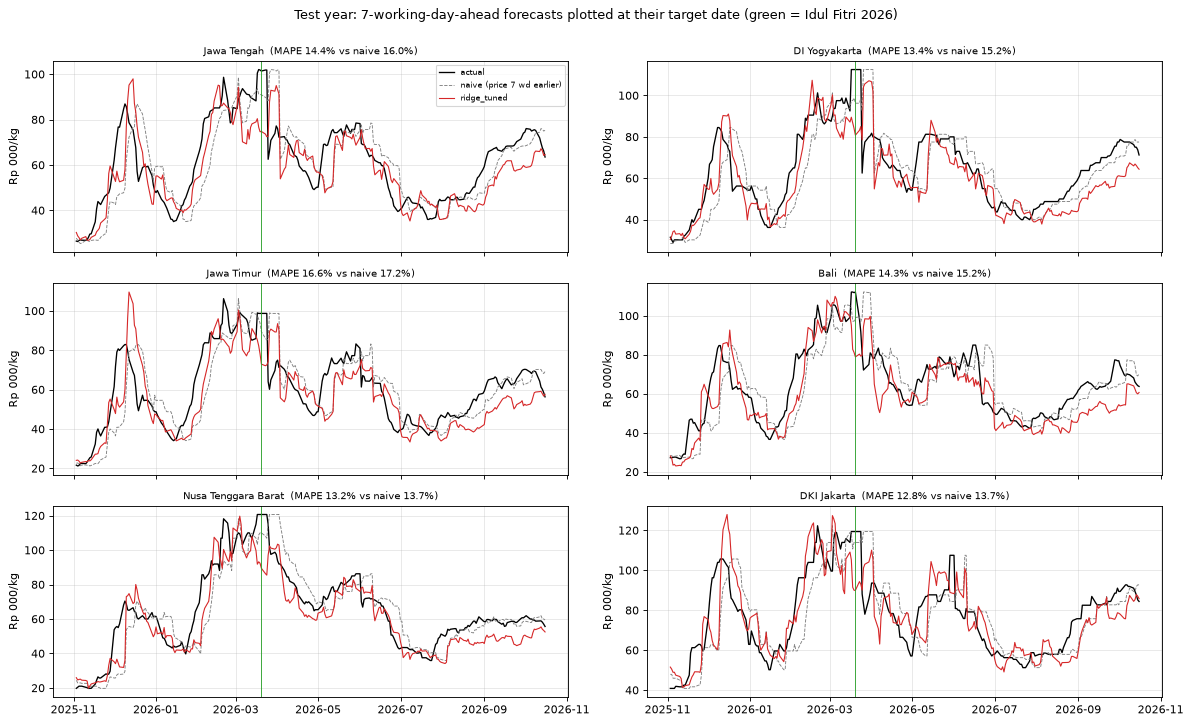

In [70]:
# Plot at the TARGET date so forecast and actual line up in time; naive shown as the benchmark to beat
fig, axes = plt.subplots(3, 2, figsize=(15, 9), sharex=True)
for ax, p in zip(axes.flat, PROVINCES):
    g_ = TEST[TEST.province == p].sort_values("target_date")
    ax.plot(g_.target_date, g_.target_price / 1000, color="k", lw=1.2, label="actual")
    ax.plot(g_.target_date, g_.p_naive / 1000, color="tab:grey", lw=.8, ls="--", label="naive (price 7 wd earlier)")
    ax.plot(g_.target_date, g_[f"p_{FINAL}"] / 1000, color="tab:red", lw=1, label=FINAL)
    for d in HOL.idul_fitri[(HOL.idul_fitri >= g_.target_date.min()) & (HOL.idul_fitri <= g_.target_date.max())]: ax.axvline(d, color="tab:green", lw=.8)
    ax.set_title(f"{p}  (MAPE {per_final.loc[p, 'MAPE']:.1f}% vs naive {per_naive.loc[p, 'MAPE']:.1f}%)", fontsize=9); ax.set_ylabel("Rp 000/kg")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Test year: 7-working-day-ahead forecasts plotted at their target date (green = Idul Fitri 2026)", y=1.0); plt.show()

What the plot shows:
* The model reacts **earlier than persistence** at turning points: it rises before the naive line at spike onsets (Nov-Dec 2025, Feb 2026) and falls earlier after peaks (Apr 2026). But it **does not anticipate the full size of the big jumps**.
* **New finding: a sustained downward bias from about August to October 2026.** While prices climb slowly from their mid-year low, the model keeps predicting falls in several provinces (JATIM, BALI, NTB, DIY). That points to features, probably the seasonal-phase rain windows and mean-reversion terms, behaving differently in 2026 than in the training years. It is quantified by month below and recorded as a limitation.
* **Flat plateaus** in the *actual* series around Idul Fitri 2026 (about 1-2 weeks of identical prices in every province) are the post-2022 holiday carry-forward reporting from Section 3.2. Forecasting a carried-forward number is not forecasting a market price.

### 11.1 Error analysis and diagnostics

First, the bias over time: mean log error by **target month** (positive = over-prediction). This checks the late-2026 pattern seen in the plot.

In [71]:
_b = TEST.assign(m=TEST.target_date.dt.to_period("M"), le=np.log(TEST[f"p_{FINAL}"] / TEST.target_price), le_naive=np.log(TEST.p_naive / TEST.target_price))
_b.groupby("m").agg(n=("le", "size"), mean_log_err_final=("le", "mean"), mean_log_err_naive=("le_naive", "mean")).round(3).T

m,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
n,120.000,138.000,132.000,120.000,132.000,132.000,126.000,132.000,138.000,126.000,132.000,72.000
mean_log_err_final,-0.028,-0.052,-0.018,-0.076,-0.058,-0.002,-0.106,0.031,-0.040,-0.166,-0.196,-0.133
mean_log_err_naive,-0.146,-0.101,0.036,-0.207,0.038,0.128,-0.114,0.152,0.034,-0.085,-0.064,0.008


Per-month bias of the final model vs naive. Naive is biased by construction during long climbs (it always lags), so the relevant comparison is whether the model's bias is **larger** than naive's in the same months. If so, it is actively predicting the wrong direction, not merely lagging.
**Result:** in August, September and October 2026 the model's mean log error is about −0.17, −0.20 and −0.13, against −0.09, −0.06 and +0.01 for naive. The model is **more biased than naive** in exactly those months: it actively predicts falls during a slow climb, rather than merely lagging.
Earlier months show no such pattern (the model's monthly bias is mostly smaller than naive's). This is a genuine late-test-year drift, worth monitoring in deployment and recorded as a limitation.

Then the errors by the size of the actual move:

In [72]:
TEST["ape_final"] = 100 * (TEST[f"p_{FINAL}"] - TEST.target_price).abs() / TEST.target_price
TEST["ape_naive"] = 100 * (TEST.p_naive - TEST.target_price).abs() / TEST.target_price
TEST["actual_move"] = np.log(TEST.target_price / TEST.price_ff)
TEST["pred_move"] = np.log(TEST[f"p_{FINAL}"] / TEST.price_ff)
TEST["log_err"] = np.log(TEST[f"p_{FINAL}"] / TEST.target_price)
# bucket by the size of the ACTUAL 7-day move: where do errors come from?
TEST["move_bucket"] = pd.cut(TEST.actual_move, [-np.inf, -0.2, -0.05, 0.05, 0.2, np.inf],
                             labels=["fall >18%", "fall 5-18%", "flat ±5%", "rise 5-22%", "rise >22%"])
TEST.groupby("move_bucket", observed=True).agg(n=("ape_final", "size"), MAPE_final=("ape_final", "mean"),
                                                MAPE_naive=("ape_naive", "mean"), mean_log_err=("log_err", "mean")).round(2)

,n,MAPE_final,MAPE_naive,mean_log_err
move_bucket,,,,
fall >18%,181,18.26,34.57,0.16
fall 5-18%,344,9.01,12.78,0.02
flat ±5%,347,10.72,2.54,-0.08
rise 5-22%,395,15.61,10.56,-0.14
rise >22%,233,20.92,30.43,-0.24


* **The model earns its keep on large moves.** For big falls (> 18%) its MAPE is 18.3% vs 34.6% for naive. For big rises (> 22%) it is 20.9% vs 30.4%. These are the weeks a stakeholder cares about.
* **It pays for that on quiet weeks.** When the actual move is within ±5%, naive is nearly perfect (2.5%) and the model is worse (10.7%), because it predicts moves that don't happen. That is the price of having a view, and it is why the overall average gain looks modest.
* The `mean_log_err` column shows the systematic failure mode: **positive on falls (over-predicting) and negative on rises (under-predicting)**. The model moves in the right direction but **shrinks the change toward zero**.
  Shrinkage is the optimal response of a model trained to minimise average error when most of the 7-day change is unpredictable. It is a property of point forecasts here, not a bug, and it is why an alert threshold is examined next instead.

In [73]:
TEST["tgt_in_ramadan_window"] = data.loc[TEST.index, "tgt_in_ramadan_window"]
hw = TEST.groupby("tgt_in_ramadan_window").agg(n=("ape_final", "size"), MAPE_final=("ape_final", "mean"), MAPE_naive=("ape_naive", "mean")).round(2)
hw.index = hw.index.map({0.0: "target outside Ramadan-Lebaran window", 1.0: "target inside window"}); hw

,n,MAPE_final,MAPE_naive
tgt_in_ramadan_window,,,
target outside Ramadan-Lebaran window,1296,14.45,15.59
target inside window,204,11.93,12.71


Ramadan-Lebaran 2026 vs the rest of the test year: inside the window the model reaches 11.9% vs naive 12.7%, and outside 14.5% vs 15.6%.
So even **without** calendar features the model beats naive in the holiday window, though by less. Part of the window's low error is the flat holiday carry-forward reporting (an easy target for naive). With a single holiday period this is anecdotal, not evidence for or against holiday features.

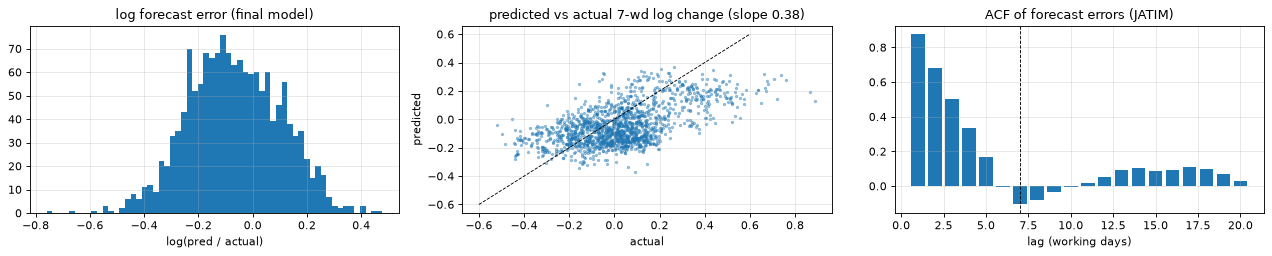

directional accuracy (sign of predicted vs actual move, |actual| > 5%): 0.691


In [74]:
# Three diagnostics: error distribution (bias/tails), predicted-vs-actual slope (shrinkage), error ACF (overlapping-horizon dependence)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.3))
ax[0].hist(TEST.log_err, bins=60); ax[0].set(title="log forecast error (final model)", xlabel="log(pred / actual)")
ax[1].scatter(TEST.actual_move, TEST.pred_move, s=4, alpha=.4); ax[1].plot([-.6, .6], [-.6, .6], "k--", lw=.8)
slope = np.polyfit(TEST.actual_move, TEST.pred_move, 1)[0]
ax[1].set(title=f"predicted vs actual 7-wd log change (slope {slope:.2f})", xlabel="actual", ylabel="predicted")
le = TEST[TEST.province == "Jawa Timur"].sort_values("date").log_err
ax[2].bar(range(1, 21), [le.autocorr(k) for k in range(1, 21)]); ax[2].axvline(H, color="k", ls="--", lw=.8)
ax[2].set(title="ACF of forecast errors (JATIM)", xlabel="lag (working days)"); plt.show()
print("directional accuracy (sign of predicted vs actual move, |actual| > 5%):",
      round(((np.sign(TEST.pred_move) == np.sign(TEST.actual_move))[TEST.actual_move.abs() > 0.05]).mean(), 3))

* **Error distribution:** centred near zero with heavy tails, the spike weeks.
* **Predicted vs actual change:** slope ≈ 0.38. The predicted move is on average about 40% of the realised move, which quantifies the shrinkage.
  **Directional accuracy on meaningful moves (> 5%) is 69%.** The model calls the direction of a real move correctly about 7 times in 10, which is the more useful number for early warning.
* **Error autocorrelation** persists up to lag ≈ 7, as expected with overlapping 7-day horizons (consecutive targets share 6 of 7 days of price evolution). The test year therefore holds far fewer *independent* errors than its 1,500 rows, so small MAPE differences between models should not be over-read.

### 11.2 Early-warning view: can the model flag big rises?

A stakeholder cares less about the exact Rupiah value than about **"will the price jump by more than 15% in the next 7 working days?"** Persistence never predicts a rise by construction, so the comparison is against a simple **momentum rule** (alert if the last 5-day rise was more than 10%).

In [75]:
act = TEST.actual_move > np.log(1.15)
rules = {"final model: predicted rise > 15%": TEST.pred_move > np.log(1.15),
         "final model: predicted rise > 8%":  TEST.pred_move > np.log(1.08),
         "final model: predicted rise > 4%":  TEST.pred_move > np.log(1.04),
         "momentum rule: ret_5 > 10%":        data.loc[TEST.index, "ret_5"] > np.log(1.10)}
rows = [{"rule": k, "alerts": int(a.sum()), "precision": (a & act).sum() / max(a.sum(), 1), "recall": (a & act).sum() / act.sum()} for k, a in rules.items()]
print(f"actual > 15% rises in the test year: {act.sum()} of {len(act)} province-origins ({act.mean():.1%})")
pd.DataFrame(rows).set_index("rule").round(3)

actual > 15% rises in the test year: 343 of 1500 province-origins (22.9%)


,alerts,precision,recall
rule,,,
final model: predicted rise > 15%,194,0.763,0.431
final model: predicted rise > 8%,297,0.653,0.566
final model: predicted rise > 4%,374,0.572,0.624
momentum rule: ret_5 > 10%,392,0.367,0.420


* About 23% of test origins are followed by a > 15% rise, so this is not a rare event.
* **The model is a much better alarm than momentum.** At "predicted rise > 15%" it raises 194 alerts with **76% precision and 43% recall**. The momentum rule catches about the same share of rises (42%) but needs twice as many alerts (392), with only 37% precision.
  So at the same coverage, the model halves the false alarms.
* Lowering the threshold trades precision for recall: at > 8% it catches 57% of rises at 65% precision, and at > 4%, 62% at 57%.
* Choosing the threshold is a **business decision**: the cost of a false alarm (an unnecessary market operation) against a missed spike. It is listed as an open decision later.

## 12. Model interpretation (predictive, **not causal**)

Two complementary views, both computed on the **test year** for interpretation only (nothing here feeds back into model choice):
1. **A model-specific view** for the final model: standardised coefficients if it is Ridge, impurity importance if Random Forest, TreeSHAP if LightGBM.
2. **Grouped permutation importance** for the final model and the runner-up: shuffle a whole feature group across rows and measure the rise in test MAPE. Groups are permuted together because the features inside a group are strongly correlated, and permuting one at a time would understate the group.

**Framing (brief Section 11):** importance means *"the model relies on this to predict"*. It does **not** mean *"this causes price changes"*. Cross-province features can matter because of arbitrage *or* because all provinces react to the same national shock with different reporting delays. No feature here has been through causal identification.

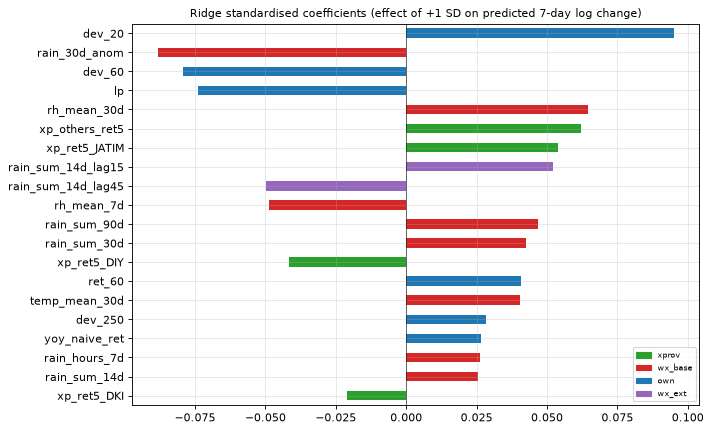

In [76]:
grp_of = {c: g_ for g_, cs in GROUPS.items() for c in cs}
grp_of.update({c: "cal" for c in CAL_LEAN})
Xt = data.loc[TEST_VA, FEATURES_FINAL]
fk = FINAL.replace("_tuned", "")
if fk == "ridge":
    coef = pd.Series(MODELS[FINAL].named_steps["ridge"].coef_, index=FEATURES_FINAL)    # per 1 SD of the feature (scaled inputs)
    native, native_title = coef, "Ridge standardised coefficients (effect of +1 SD on predicted 7-day log change)"
elif fk == "rf":
    native = pd.Series(MODELS[FINAL].named_steps["randomforestregressor"].feature_importances_, index=FEATURES_FINAL)
    native_title = "Random Forest impurity importance"
elif fk == "lgbm":
    native = pd.Series(np.abs(MODELS[FINAL].predict(Xt, pred_contrib=True)[:, :-1]).mean(0), index=FEATURES_FINAL)
    native_title = "LightGBM mean |TreeSHAP| on test"
else:
    native = None; print("final model is univariate (ETS/ARIMA): no feature-level view")
if native is not None:
    top = native.reindex(native.abs().sort_values(ascending=False).index).head(20)[::-1]
    pal = dict(zip(GROUPS, sns.color_palette("tab10", len(GROUPS))))
    fig, ax = plt.subplots(figsize=(9, 5.5))
    top.plot.barh(ax=ax, color=[pal[grp_of[c]] for c in top.index]); ax.axvline(0, color="k", lw=.5)
    ax.set_title(native_title, fontsize=10)
    from matplotlib.patches import Patch
    present = list(dict.fromkeys(grp_of[c] for c in top.index))
    ax.legend(handles=[Patch(color=pal[g_], label=g_) for g_ in present], fontsize=7, loc="lower right"); plt.show()

This is the model-specific view: the top 20 features, coloured by group. For a Ridge model the **sign** is interpretable: a positive coefficient means a higher value of the feature goes with a higher predicted 7-day change, holding the other (correlated) features fixed.
With strongly correlated lag features that "holding fixed" is fragile, so the grouped permutation view below is the more robust summary.

What the coefficients show for the final (Ridge) model:
* **Own-price terms carry a momentum-plus-reversion structure.** `dev_20` (price above its 1-month mean) is **positive**: recent strength predicts more strength, matching the 7-day momentum of Section 5.3. `dev_60` and `lp` (price high relative to the quarter, or high in absolute terms) are **negative**: very high prices predict reversion.
* **Cross-province terms**: `xp_others_ret5` and `xp_ret5_JATIM` are **positive**. A recent rise elsewhere, and in Jawa Timur in particular, predicts a rise here (Section 5.6).
* **Weather terms** have large coefficients of **mixed sign** (e.g. `rain_30d_anom` negative while `rain_sum_90d` and `rh_mean_30d` are positive). Rain windows are strongly correlated with each other, so individual signs here are **not interpretable on their own**. Only the group's combined effect is (next two cells).

In [77]:
rng = np.random.default_rng(SEED)
def perm_importance(name, n_rep=5):
    m_ = MODELS[name]
    def mape_with(X): return metrics(TEST.assign(_p=TEST.price_ff * np.exp(m_.predict(X))), "_p")[1]["MAPE"]
    base = mape_with(Xt); out = {}
    for g_ in dict.fromkeys(grp_of[c] for c in FEATURES_FINAL):
        cols = [c for c in FEATURES_FINAL if grp_of[c] == g_]; sc = []
        for _ in range(n_rep):
            Xp = Xt.copy(); Xp[cols] = Xt[cols].values[rng.permutation(len(Xt))]; sc.append(mape_with(Xp) - base)
        out[g_] = np.mean(sc)
    return pd.Series(out)
# comparison model = best CV model from a DIFFERENT family, so we can see whether conclusions depend on the model type
fam = lambda n: n.replace("_tuned", "")
runner = next((m for m in all_cv.index if m in MODELS and fam(m) != fam(FINAL)), None)
ml_names = [n for n in [FINAL, runner] if n in MODELS]
PERM = pd.DataFrame({n: perm_importance(n) for n in ml_names}).sort_values(ml_names[0], ascending=False)
print("increase in test MAPE (percentage points) when a whole group is shuffled:"); PERM.round(3)

increase in test MAPE (percentage points) when a whole group is shuffled:


,ridge_tuned,lgbm_tuned
wx_ext,1.999,1.700
own,1.513,1.988
xprov,0.129,0.615
wx_base,-0.008,0.890
prov,-0.044,0.027


Grouped permutation importance answers *"how much worse would the forecast be if this information were scrambled?"* Values near zero mean the model barely relies on the group; negative values mean the group was adding noise on the test year.
Comparing the final model with the runner-up shows whether the conclusions depend on the model family.

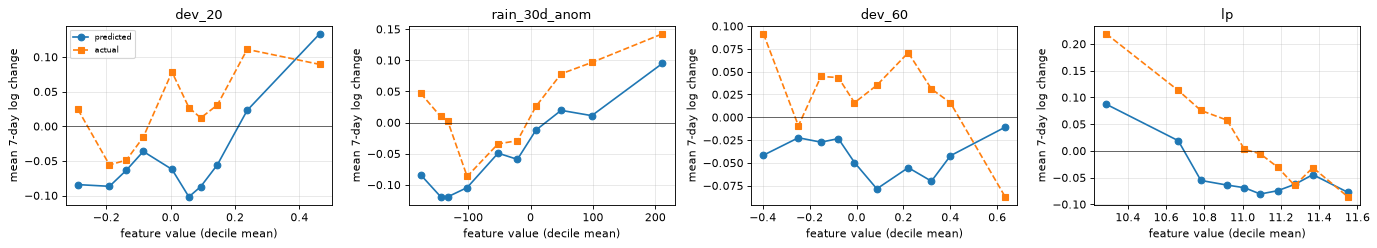

In [78]:
# Model response: binned average PREDICTED vs ACTUAL 7-day change against the most relied-on features (model-agnostic)
if native is not None:
    show = [c for c in native.abs().sort_values(ascending=False).index if not c.startswith("prov_")][:4]
    fig, axes = plt.subplots(1, len(show), figsize=(4.3 * len(show), 3.2))
    for ax, c in zip(axes, show):
        b = pd.qcut(Xt[c], 10, duplicates="drop")
        gr = TEST.assign(b=b.values).groupby("b", observed=True)
        x = Xt[c].groupby(b, observed=True).mean()
        ax.plot(x.values, gr.pred_move.mean().values, "o-", label="predicted"); ax.plot(x.values, gr.actual_move.mean().values, "s--", label="actual")
        ax.axhline(0, color="k", lw=.5); ax.set(title=c, xlabel="feature value (decile mean)", ylabel="mean 7-day log change")
    axes[0].legend(fontsize=7); plt.show()

**Interpretation (predictive language only):**
* **Lagged rain and own price carry most of the final model's accuracy.** Shuffling the data-driven lagged rain windows (`wx_ext`) raises the tuned Ridge's test MAPE by about 2.0 pp and own-price features by about 1.5 pp. The tuned LightGBM relies on the same two groups (own price ≈ 2.0 pp, lagged rain ≈ 1.7 pp). This is the opposite of the "weather adds little" expectation, and it is driven by the lagged windows found in Section 5.7, not by the original fixed ones.
  The response plots show, for example, that higher recent rain anomaly goes with higher *realised* and *predicted* 7-day changes, and that a high price level goes with falls.
* **The base weather group splits the two families.** For tuned Ridge, shuffling `wx_base` changes nothing (−0.01 pp): its large, mixed-sign coefficients cancel out, matching its near-zero ablation effect in Section 9.3. Tuned LightGBM, by contrast, relies on it (≈ 0.9 pp).
* **Cross-province features matter much more to the tree model than to Ridge.** In tuned LightGBM, shuffling them costs about 0.6 pp of test MAPE, against about 0.13 pp for Ridge (and in the Section 9.3 ablation removing them cost RF/LightGBM about 0.5-0.9 pp but Ridge only 0.16 pp). The "Jawa Timur leads" signal seems to be partly non-linear (e.g. it matters most when JATIM moves sharply), which a linear model captures only partly.
* Where the actual line in the response plots is much steeper than the predicted line, the model under-reacts. This is the shrinkage of Section 11.1 seen feature by feature.
* All of these statements are about **predictive association on 2025-26 data**. Rain features can be important because rain marks the season (and through it supply), and cross-province features can be important because of arbitrage *or* because a common shock is reported at different speeds. Neither is established as a cause.

## 13. Actionable insights and business implications (DRAFT, for the group to refine)

All numbers referenced are produced by the cells above. The wording is a first draft for the pitch.

| # | Finding | Evidence | Actionable insight (for TPID / provincial trade office) | Business implication |
|---|---|---|---|---|
| 1 | The model beats persistence **in every CV fold and every province of the unseen test year** (test MAPE 14.1% vs 15.2%), and its value is concentrated in **big moves and direction** (69% directional accuracy on moves > 5%) | Section 9.4, Section 11 tables, Section 11.1 | Use the predicted 7-day change as an **early-warning score**: "predicted rise > 15%" flagged rises with **76% precision** (vs 37% for a simple momentum rule at the same recall) | Market operations and stock transfers can be triggered by alerts with a known false-alarm rate, about half that of watching recent momentum |
| 2 | **Jawa Timur leads**: its recent price move predicts other provinces' next-week moves better than their own history, and cross-province features are the most valuable engineered group in the ablation (largest for the tree models) | Section 5.6, Section 9.3, Section 12 | Monitor Jawa Timur (the largest producer) **daily as a leading indicator**. A sharp JATIM rise is a reason to check supply in consumer provinces (DKI, Bali, NTB, DIY) | Supports inter-province supply cooperation (*kerja sama antar daerah*) and a shared early-warning view across TPIDs, rather than each province watching only itself |
| 3 | **Lagged rainfall carries real 7-day signal**: wet spells 2-4 weeks ago go with higher prices, rain 6-7 weeks ago with subsequent falls. These windows are the final model's most relied-on group | Section 5.7, Section 9.3, Section 12 | Add **rainfall over the past 2-7 weeks** (BMKG observations) to the TPID monitoring dashboard as a context signal for the price alert | Weather data the agencies already have becomes actionable at a 1-2 week horizon, not only for seasonal planning |
| 4 | The conventional **pre-Lebaran price surge is not visible** for cabai rawit in 2017-2025, and holiday-calendar features made forecasts **worse**. The big seasonal rise is around Dec-Jan (rainy-season onset) | Section 5.9, Section 9.3 | Don't time chili interventions **only** on the Lebaran calendar. Watch the **December rainy-season onset** at least as closely, and let the price/weather alert decide timing | Holiday-season readiness still matters for other commodities, but for chili the early-warning budget is better aimed at the rainy-season window |
| 5 | Reporting quality varies: DKI Jakarta and DIY repeat the identical price on 42-45% of days, and since Aug 2022 holiday prices appear to be carried forward | Section 3.2, Section 3.4, Section 11 plot | Ask the PIHPS data owners how those provinces' prices are collected, and flag carried-forward days in the data | Data governance: forecast quality is capped by reporting quality, and a "price" on a closed-market day is not a market signal |

**Implementation considerations.** The pipeline uses only public data (PIHPS, Open-Meteo, a cited fuel-price table, a holiday calendar) and runs in minutes on a laptop, so it could be refreshed daily after PIHPS publishes and retrained monthly on the expanding window, mirroring the validation design.
Any deployment should track live MAPE **and bias** against the naive benchmark (the August-October 2026 drift in Section 11 is exactly what monitoring should catch) and fall back to persistence if the model stops beating it.

## 14. Limitations (consolidated)

All limitations in one place, so a reviewer can read them end to end.

**Framing and design**
1. **Predictive, not causal.** This is forecasting on observational data. Feature importance shows what the model *relies on*, not what *causes* price changes (Section 12). The named mechanisms (weather → supply, holidays → demand, arbitrage, transport cost) are plausible stories, not tested effects.
2. **Province selection includes one deliberate non-statistical choice.** Five provinces were screened on coverage ≥ 93% *and* volatility (CV). **DKI Jakarta was added afterwards** as a demand-anchor market despite the lowest CV (40.6%).
   Section 5.5 finds it follows the same cycle but is smoother, partly because of stale reporting. Jakarta's results should be read with that in mind, and the macro-average mixes an "easier" province with harder ones.
3. **Point forecasts shrink large moves** (Section 11.1). Prediction intervals / quantile forecasts are not yet implemented.
4. **Small effective evaluation sample.** The test year is about 250 origins × 6 provinces with autocorrelated (overlapping-horizon) errors, and the CV blocks contain only two Ramadan periods. Small differences between models, and the holiday-feature verdict, are within noise.
5. **The CV-selected model was not the best on test** (tuned Ridge 14.11% vs tuned LightGBM 13.00%). Selection followed the pre-declared rule, but the 1.1 pp gap is larger than typical noise between models here, and default Ridge (13.68%) also beat the tuned one, so the 6-year training window chosen in CV did not carry over. The choice between Ridge, LightGBM or an average of the two is not settled.
6. **Sustained bias in mid/late 2026** (Section 11): from about August to October 2026 the model under-predicts a slow price climb in several provinces. It needs monitoring and possibly retraining on a shorter, more recent window.
7. **Feature-group decisions use one ablation pass** with default hyperparameters (Section 9.3). Interactions between feature choice and tuning are not explored, so a tuned LightGBM might use the calendar or radiation/ET0 features better, for example. Several group effects are small (base weather +0.03 pp, radiation/ET0 −0.12 pp, Solar −0.17 pp) and their keep/drop status could flip with a different data vintage.

**Data**
8. **PIHPS is an aggregate *reported* price** (province average of sampled traditional markets), not transaction data. Missing days (≈ 2-4%, almost all public holidays) are forward-filled for features and excluded as targets.
9. **Stale / sticky reporting** (new finding, Section 3.4): 45% (DKI Jakarta) and 42% (DI Yogyakarta) of consecutive reports repeat the identical value, vs about 4-5% in Jawa Tengah/Timur. This understates true volatility in those provinces and limits what any model can learn there.
10. **Reporting-practice break** (new finding, Section 3.2): no province leaves a holiday blank after 17 Aug 2022, so holidays are presumably carried forward since then. Pre- and post-2022 data are not fully comparable, and part of the test year (flat plateaus around Lebaran 2026) is a reported, not traded, price.
11. **Large one-day jumps that reverse next day** exist (1-3 per province, Section 3.3). Data-entry errors could not be told apart from real one-day squeezes without market-level data. They were kept.
12. **Different start dates per province** (Apr-Oct 2017). Early data are sparser.

**Features**
13. **Weather is measured at the provincial capital**, i.e. where the market price is reported, **not in the chili-growing regions** (e.g. the highland production areas). Weather at the point of consumption need not match weather at the point of production, which probably weakens the weather signal.
    ERA5 is reanalysis: recent days get revised, so a live system would see slightly different values than this backtest.
14. **Weather-window scan** (Section 5.7) correlates seasonal series. Rain and price share an annual cycle and Ramadan has moved into the rainy season during 2017-2026, so the scan is a screening tool, not evidence of a weather effect.
    The extra lagged windows were chosen on dev-period data only, but they are still chosen from the same data they are evaluated on in CV, so the CV gain of `wx_ext` is mildly optimistic. They remained the top permutation group for the final model (and second for tuned LightGBM) on the locked test year, which suggests the signal is real.
15. **Solar (BBM) is experimental and not in the final model**: although it is now a regular, complete column of the modelling panel (all six provinces, six `confirmed` events in the source table), it has only two price levels inside the panel (one event, Sept 2022), is indistinguishable from a date/trend feature, and is constant throughout CV and test. A future price change would be the first real test of the transport-cost story.
16. **Holiday dates:** Ramadan/Idul Fitri/Idul Adha come from the Umm al-Qura conversion (`hijridate`), which can differ by ±1 day from the Indonesian *sidang isbat* dates. The government dates in the comparison table were **recalled, not verified in this session**.
    **Imlek dates are hard-coded, verified against 4 independent calendar sources (vclock.com, Herong Yang, USC US-China Institute, a holiday API), exact agreement for all 12 years.** `tgt_holidays_in_window` uses observed closure days as a stand-in for the official SKB calendar.
17. **Cross-province features use `MIN_LAG` = 1 day** (conservative). Whether other provinces' same-day prices are available at forecast time was not checked against PIHPS publication timing. A common national shock reported at different speeds would look like a "lead" in Section 5.6.
18. **Rejected candidates** (documented in Section 6.7, not silently omitted): IDR/USD (no clean fast causal path to 7-day spikes, confounding risk), BNPB disaster data (annual-aggregate granularity, no event-level API, the one event log covers 1 of 6 provinces), windspeed (noisy, threshold-type damage).

**Reproducibility**
19. All inputs are read from one folder (`DATA_DIR` = `../pihps-cabai-rawit-forecast/dataset/`). For the submission ZIP, copy those dataset files next to the notebook and reduce `DATA_DIR` to one relative path (brief Section 12). Full run time is about 8 minutes on a laptop, mostly the feature ablation and tuning.

## 15. Decisions (confirmed by the group)

**All proposals in this draft have been reviewed and confirmed:**
1. **Primary metric = macro-averaged MAPE** (MAE/RMSE as support). Section 8. **Confirmed.**
2. **ML target = 7-day log change, back-transformed.** Section 3.5. **Confirmed.**
3. **Validation layout:** 1-year locked test (fixed in Section 4.4, before EDA), 5 × 6-month expanding-window folds, 7-day purge. Section 7. **Confirmed.**
4. **Solar encoding = one raw `solar_rp_per_l` column** (the flag is provably equivalent). Excluded from the final model by the ablation (mean −0.17 pp, only 1 of 3 families helped). Section 6.6, Section 9.3. **Confirmed: excluded.** It stays in the panel, so re-including it is a one-line change if a future price level appears.
5. **Calendar feature set and windows** (Ramadan − 14 d → Lebaran + 3 d; post-Lebaran + 4…21 d; Nataru 10 Dec - 5 Jan). Built, but **dropped by the ablation** (worse in all 3 families), consistent with the event study finding no stable pre-Lebaran surge. Section 5.9, Section 6.5, Section 9.3. **Confirmed: dropped**, on the strength of two independent lines of evidence agreeing (event study + ablation).
6. **Data-driven lagged rain windows** (kept: help in all 3 families) and **radiation/ET0** (the panel's `srad_mean`/`et0_mean` 7/30-day columns, no custom windows; **dropped**: they helped only RF). Section 5.7-5.8, Section 9.3. **Confirmed.**
7. **Feature-group keep rule:** mean CV gain across 3 model families **and** ≥ 2 of 3 families agree. Base weather passes it only narrowly (+0.03 pp) but is kept regardless, being cheap and physically well-motivated. Section 9.3. **Confirmed.**
8. **Final model = lowest CV MAPE (tuned Ridge),** test reported once. On test, tuned LightGBM was better by 1.1 pp (13.00% vs 14.11%), and default Ridge also beat tuned Ridge, but switching models based on test performance would turn the test set into a second validation set. Section 11. **Confirmed: tuned Ridge is the final model**, selected strictly by the pre-declared CV rule. No Ridge + LightGBM ensemble evaluation was run; the test-year gap is recorded as a limitation (Section 14) rather than acted on.